# Pregunta 3. Monitoreo de fauna silvestre con cámaras trampa (YOLOv8)

**Curso:** Redes Neuronales y Aprendizaje Profundo, UNI FIIS 2026-II. Examen parcial, Pregunta 3.

Este cuaderno documenta el estudio completo de la Pregunta 3, ejecutado en Colab sobre una GPU T4. Se compararon dos detectores YOLOv8-s
preentrenados en COCO que difieren en el número de cámaras de entrenamiento:

| Modelo | Entrenamiento | Propósito |
|---|---|---|
| **A** | `train` de CCT-20: las 10 cámaras cis de la partición oficial `eccv_train` | Protocolo del enunciado y de Beery et al. (2018) |
| **B** | A más las cámaras externas del `train` general de CCT que contienen cajas de las 15 clases (46 de 90), tomadas del conjunto completo | Ablación sobre la diversidad de cámaras |

Ambos modelos comparten la validación (`cis_val ∪ trans_val`), el criterio de umbral y los conjuntos de prueba:

* **cis:** cámaras vistas.
* **trans:** las 9 cámaras nuevas de la partición oficial.
* **trans ampliado:** 30 cámaras externas del `val` general, con sus vacías ponderadas.
* **ENA24-detection:** otra región.

**Hallazgos principales**

* En cámaras nuevas, A obtiene un mAP@0.5 de 40.6 % frente a 66.6 % en cámaras vistas, lo que equivale a un incremento relativo del error del 78 %.
* B mejora todos los dominios: +7.8 puntos en trans y +30.7 en el trans ampliado. Sin embargo, la brecha frente a las cámaras trans persiste, porque B también mejora en cis.
* La caída se concentra en la clasificación y en la pérdida de separabilidad entre vacías y fauna.
* El tamaño del objeto es el factor de dificultad dominante.

**Reproducción.** Ejecuta todo con *Ejecutar todas*. Cada etapa deja una marca en `MyDrive/P3_CCT20/estado`, los entrenamientos se
reanudan desde `last.pt` y las descargas e inferencias continúan por bloques. Con `MODO_PRUEBA = True` el flujo completo se recorre en CPU
sobre un conjunto sintético con la misma estructura de archivos.

## 0. Configuración

In [2]:
# ===================== CONFIGURACIÓN GENERAL =====================
MODO_PRUEBA = False      # True: conjunto sintético mínimo, CPU, verificación del flujo

CFG = dict(
    modelo='yolov8s.pt', imgsz=640, epochs=50, patience=15, batch=16, workers=2, seed=0,
    frac_fondo=0.10,            # fracción objetivo de vacías en el entrenamiento (limitada por las disponibles en CCT-20)
    modelos=('A', 'B'),         # A: solo CCT-20 (eccv_train); B: A + 91 cámaras externas del train general
    k_vacias_ext=3,             # trans ampliado: se descarga 1 de cada k vacías y se pondera por k (Horvitz-Thompson)
    max_demo=6000,              # tamaño máximo del flujo de la cámara de demostración
    hilos_descarga=32,
    conf_eval=0.001, iou_nms=0.7, max_det=100, batch_inf=32, chunk=2000,
    cam_capas=(9, 6), n_cam=250, n_contrafactual=300, n_boot=300,
    usar_ena24=True,
    simular_caida_en_epoca=None,  # solo pruebas: provoca una caída del primer entrenamiento tras esa época
)
if MODO_PRUEBA:
    CFG.update(imgsz=320, epochs=3, patience=3, batch=8, workers=0, batch_inf=8, chunk=40,
               n_cam=10, n_contrafactual=10, n_boot=20, max_demo=200, hilos_descarga=4)

In [3]:
import os, sys, json, glob, math, time, random, shutil, tarfile, zipfile, subprocess, re, warnings, io, urllib.request
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
EN_COLAB = 'google.colab' in sys.modules

if EN_COLAB and not MODO_PRUEBA:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK = '/content/drive/MyDrive/P3_CCT20'    # persistente: pesos, cachés, predicciones, resultados
    LOCAL = '/content/p3'                        # disco local rápido: imágenes y conjuntos YOLO
else:
    base = '/content' if EN_COLAB else os.getcwd()
    WORK = os.path.join(base, 'p3_work_prueba' if MODO_PRUEBA else 'p3_work')
    LOCAL = os.path.join(WORK, 'local')

RES, PRED, RUNS, CACHE, ESTADO = (f'{WORK}/{d}' for d in ['resultados', 'predicciones', 'runs', 'cache', 'estado'])
for d in [WORK, LOCAL, RES, PRED, RUNS, CACHE, ESTADO, f'{WORK}/modelos', f'{WORK}/ckpt']:
    Path(d).mkdir(parents=True, exist_ok=True)
print('WORK =', WORK, '| LOCAL =', LOCAL, '| Colab:', EN_COLAB, '| prueba:', MODO_PRUEBA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WORK = /content/drive/MyDrive/P3_CCT20 | LOCAL = /content/p3 | Colab: True | prueba: False


In [4]:
def _instalar():
    try:
        import ultralytics, pycocotools  # noqa
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.3.253', 'pycocotools'], check=True)
_instalar()

import numpy as np, pandas as pd, cv2, torch
import matplotlib; import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
from sklearn.metrics import roc_auc_score
import ultralytics
from ultralytics import YOLO
warnings.filterwarnings('ignore', category=FutureWarning); warnings.filterwarnings('ignore', message='Mean of empty slice')
random.seed(CFG['seed']); np.random.seed(CFG['seed']); torch.manual_seed(CFG['seed'])
DEV = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print('ultralytics', ultralytics.__version__, '| torch', torch.__version__, '| dispositivo', DEV,
      torch.cuda.get_device_name(0) if DEV != 'cpu' else '')

ultralytics 8.3.253 | torch 2.11.0+cu130 | dispositivo cuda:0 Tesla T4


In [5]:
# ---------- utilidades: estado, figuras, tablas LaTeX ----------
def hecho(n):  return os.path.exists(f'{ESTADO}/{n}.json')
def marcar(n, info=None):
    with open(f'{ESTADO}/{n}.json', 'w') as f: json.dump(info or {}, f, indent=1, default=str)
def leer_marca(n):
    with open(f'{ESTADO}/{n}.json') as f: return json.load(f)

plt.rcParams.update({
    'font.family': 'STIXGeneral', 'mathtext.fontset': 'stix', 'font.size': 9, 'axes.titlesize': 9, 'axes.labelsize': 9,
    'legend.fontsize': 7.5, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .25, 'grid.linewidth': .5, 'pdf.fonttype': 42,
    'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02, 'lines.linewidth': 1.2})
COL = {'cis': '#1f3b5c', 'trans': '#b5523b', 'trans_ext': '#c98b2b', 'ena24': '#5b7f4a', 'gris': '#8a8f98', 'claro': '#c9d3df',
       'A': '#1f3b5c', 'B': '#b5523b'}
DOMCOL = {'cis_test': COL['cis'], 'trans_test': COL['trans'], 'trans_ext': COL['trans_ext'], 'ena24': COL['ena24']}
NOMDOM = {'cis_test': 'cis', 'trans_test': 'trans', 'trans_ext': 'trans ampliado', 'ena24': 'ENA24'}
SUF = {'cis_test': 'Cis', 'trans_test': 'Trans', 'trans_ext': 'Ext', 'ena24': 'Ena'}
ANCHO = 5.5

def guardar_fig(fig, nombre):
    fig.savefig(f'{RES}/{nombre}.pdf'); fig.savefig(f'{RES}/{nombre}.png', dpi=120); plt.show(); plt.close(fig)

MACROS_JSON = f'{RES}/metricas.json'
def macro(nombre, valor):
    """Registra \\nombre en resultados/metricas.tex (solo letras)."""
    assert re.fullmatch(r'[A-Za-z]+', nombre), nombre
    d = json.load(open(MACROS_JSON)) if os.path.exists(MACROS_JSON) else {}
    d[nombre] = str(valor); json.dump(d, open(MACROS_JSON, 'w'), indent=1)
    with open(f'{RES}/metricas.tex', 'w') as f:
        f.write('% Generado por el cuaderno P3. No editar a mano.\n')
        for k, v in sorted(d.items()): f.write(f'\\def\\{k}{{{v}}}\n')

def pct(x, nd=1):
    try: x = float(x)
    except Exception: return '--'
    return f'{100 * x:.{nd}f}' if np.isfinite(x) else '--'
def num(x):  return f'{int(x):,}'.replace(',', '\\,')
def tex_esc(s): return str(s).replace('_', '\\_').replace('%', '\\%').replace('&', '\\&')

def tabla_tex(filas, cabecera, nombre, alin=None, grupos=None):
    alin = alin or ('l' + 'r' * (len(cabecera) - 1))
    L = [f'\\begin{{tabular}}{{{alin}}}', '\\toprule'] + ([grupos] if grupos else []) + [' & '.join(cabecera) + r' \\', '\\midrule']
    for r in filas: L.append('\\midrule' if r == 'MIDRULE' else ' & '.join(r) + r' \\')
    L += ['\\bottomrule', '\\end{tabular}']
    with open(f'{RES}/{nombre}.tex', 'w') as f: f.write('\n'.join(L) + '\n')
    print('\n'.join(L))

## 1. Datos

El estudio combina cuatro archivos de LILA BC con descargas puntuales del conjunto completo:

| Recurso | Uso |
|---|---|
| `eccv_18_all_images_sm.tar.gz` (6 GB) | Imágenes de CCT-20 (lado máximo de 1024 px) |
| `eccv_18_annotations.tar.gz` | Particiones `train`, `cis_val`, `cis_test`, `trans_val` y `trans_test` |
| `caltech_camera_traps.json.zip` | Metadatos de todas las imágenes de CCT: ubicación, fecha, secuencia y especie |
| `caltech_bboxes_20200316.json` | Cajas del conjunto completo |
| `CaltechCameraTrapsSplits_v0.json` | Partición oficial `eccv_train/eccv_val` y partición general `train/val` por ubicación |
| `caltech-unzipped/cct_images/` | Conjunto completo de 105 GB descomprimido en el bucket. Solo se descargan las imágenes necesarias |

Todas las imágenes se reescalan una única vez al lado mayor de 640 px y se guardan en Drive como `.tar`. De ese modo las sesiones
posteriores solo extraen el archivo, y una caída durante la descarga obliga a repetir únicamente el bloque en curso.

In [6]:
S = CFG['imgsz']
LILA = 'https://storage.googleapis.com/public-datasets-lila'
URL = {
    'imgs':   f'{LILA}/caltechcameratraps/eccv_18_all_images_sm.tar.gz',
    'anot':   f'{LILA}/caltechcameratraps/eccv_18_annotations.tar.gz',
    'imagen': f'{LILA}/caltechcameratraps/labels/caltech_camera_traps.json.zip',
    'bboxes': f'{LILA}/caltechcameratraps/labels/caltech_bboxes_20200316.json',
    'splits': f'{LILA}/caltechcameratraps/CaltechCameraTrapsSplits_v0.json',
    'base_completo': f'{LILA}/caltech-unzipped/cct_images/',
    'ena_json': f'{LILA}/ena24/ena24.json',
    'ena_zip':  f'{LILA}/ena24/ena24.zip',
}

def descargar(url, destino, intentos=5):
    Path(destino).parent.mkdir(parents=True, exist_ok=True)
    for i in range(intentos):
        if subprocess.run(['wget', '-c', '-q', '--show-progress', '-O', destino, url]).returncode == 0: return destino
        print('reintento', i + 1); time.sleep(5)
    raise RuntimeError(f'No se pudo descargar {url}')

def extraer(archivo, destino):
    Path(destino).mkdir(parents=True, exist_ok=True)
    if archivo.endswith('.zip'):
        with zipfile.ZipFile(archivo) as z: z.extractall(destino)
    else:
        with tarfile.open(archivo) as t: t.extractall(destino)

def indexar_jpg(raiz):
    idx = {}
    for dp, _, fs in os.walk(raiz):
        for f in fs:
            if f.lower().endswith(('.jpg', '.jpeg', '.png')): idx[os.path.splitext(f)[0]] = os.path.join(dp, f)
    return idx

def _guardar_redim(im, dst, s):
    im = im.convert('RGB'); w, h = im.size; r = s / max(w, h)
    if r < 1: im = im.resize((round(w * r), round(h * r)), Image.LANCZOS, reducing_gap=2.0)
    im.save(dst, quality=93); return im.size[0], im.size[1], w, h

def _redimensionar(args):
    src, dst, s = args
    try:
        im = Image.open(src); im.load(); return (os.path.basename(dst)[:-4],) + _guardar_redim(im, dst, s)
    except Exception as e:
        print('error', src, e); return os.path.basename(dst)[:-4], -1, -1, -1, -1

def preparar_imagenes(nombre, raiz_cruda_fn, s=S):
    """Conjunto descargado como archivo (CCT-20, ENA24): redimensiona una vez y guarda un .tar en Drive."""
    dst = f'{LOCAL}/{nombre}_{s}'; tar_drive = f'{CACHE}/{nombre}_{s}.tar'; dims_csv = f'{CACHE}/{nombre}_{s}_dims.csv'
    if os.path.exists(f'{dst}/.listo'): return dst, pd.read_csv(dims_csv, dtype={'id': str})
    if os.path.exists(tar_drive) and os.path.exists(dims_csv):
        print('Extrayendo caché de Drive', tar_drive); lt = f'{LOCAL}/{nombre}_{s}.tar'
        shutil.copy(tar_drive, lt); extraer(lt, LOCAL); os.remove(lt); Path(f'{dst}/.listo').touch()
        return dst, pd.read_csv(dims_csv, dtype={'id': str})
    raiz = raiz_cruda_fn(); idx = indexar_jpg(raiz); Path(dst).mkdir(parents=True, exist_ok=True)
    print(f'Redimensionando {len(idx)} imágenes a {s} px'); t0 = time.time()
    from multiprocessing import Pool
    with Pool(max(1, os.cpu_count())) as pool:
        out = list(pool.imap_unordered(_redimensionar, [(p, f'{dst}/{k}.jpg', s) for k, p in idx.items()], chunksize=64))
    dims = pd.DataFrame(out, columns=['id', 'w', 'h', 'ow', 'oh']); dims = dims[dims.w > 0]
    dims.to_csv(dims_csv, index=False); print(f'{time.time() - t0:.0f} s')
    with tarfile.open(f'{LOCAL}/{nombre}_{s}.tar', 'w') as t: t.add(dst, arcname=os.path.basename(dst))
    shutil.move(f'{LOCAL}/{nombre}_{s}.tar', tar_drive); shutil.rmtree(raiz, ignore_errors=True)
    Path(f'{dst}/.listo').touch()
    return dst, dims

In [7]:
# ---------- conjunto sintético (solo MODO_PRUEBA): misma estructura de archivos que CCT-20, CCT completo y ENA24 ----------
def _textura(rng, W, H, tinte):
    base = cv2.resize(rng.random((H // 25 + 2, W // 25 + 2, 3)).astype(np.float32), (W, H), interpolation=cv2.INTER_CUBIC)
    img = (60 + 120 * base) * np.array(tinte)[None, None, :]
    for _ in range(4):
        c = (int(rng.integers(0, W)), int(rng.integers(H // 2, H))); ax = (int(rng.integers(15, 50)), int(rng.integers(8, 25)))
        cv2.ellipse(img, c, ax, 0, 0, 360, tuple(float(v) for v in 0.45 * img[c[1] % H, c[0] % W]), -1)
    return np.clip(img, 0, 255).astype(np.uint8)

def generar_sintetico(raiz):
    rng = np.random.default_rng(0)
    clases = ['opossum', 'raccoon', 'coyote', 'bobcat', 'deer']
    color = {'opossum': (205, 205, 195), 'raccoon': (85, 85, 90), 'coyote': (175, 135, 85), 'bobcat': (140, 95, 60),
             'deer': (150, 110, 70), 'lizard': (90, 140, 60)}
    asp = {'opossum': 1.6, 'raccoon': 1.3, 'coyote': 1.9, 'bobcat': 1.5, 'deer': 1.2, 'lizard': 2.5}
    cats = [{'id': 0, 'name': 'empty'}] + [{'id': i + 1, 'name': c} for i, c in enumerate(clases + ['lizard'])]
    cid = {c['name']: c['id'] for c in cats}
    # 1-6: CCT-20 (1-3 cis, 4 trans_val, 5-6 trans_test); 7-9: externas train general; 10-11: externas val general
    locs = {1: 'train', 2: 'train', 3: 'train', 4: 'trans_val', 5: 'trans_test', 6: 'trans_test',
            7: 'ext_tr', 8: 'ext_tr', 9: 'ext_tr', 10: 'ext_va', 11: 'ext_va'}
    W, H = 400, 300
    d_img = f'{raiz}/eccv_18_all_images_sm'; d_an = f'{raiz}/eccv_18_annotation_files'; d_full = f'{raiz}/cct_images'
    for d in [d_img, d_an, d_full]: Path(d).mkdir(parents=True, exist_ok=True)
    spl = ['train', 'cis_val', 'cis_test', 'trans_val', 'trans_test']
    I = {k: [] for k in spl}; A = {k: [] for k in spl}; FI, FA, BA = [], [], []
    t0 = pd.Timestamp('2013-05-01'); n = 0; na = 0
    for l, rol in locs.items():
        fondo = _textura(rng, W, H, rng.uniform(0.7, 1.1, 3)); externa = rol.startswith('ext')
        p_vacia = .65 if externa else .1
        for s in range(18 if externa else 16):
            dia = int(rng.integers(1, 9)); hora = int(rng.integers(0, 24)); noche = hora < 6 or hora >= 19
            split = rol if rol != 'train' else ('cis_test' if dia % 2 else ('cis_val' if rng.random() < .15 else 'train'))
            pool = clases if externa else clases[:4]
            cls = None if rng.random() < p_vacia else str(rng.choice(pool + (['lizard'] if externa else [])))
            nan_ = 0 if cls is None else (2 if rng.random() < .15 else 1)
            anim = []
            for a in range(nan_):
                h = float(rng.uniform(12, 90)); w = h * asp[cls]
                anim.append([float(rng.uniform(-10, W - w + 10)), float(rng.uniform(H * .35, H - h + 5)), w, h, float(rng.uniform(-25, 25))])
            arbusto = rng.random() < .3
            for f in range(3):
                img = fondo.astype(np.float32) * (0.55 if noche else 1.0) + rng.normal(0, 6, fondo.shape); cajas = []
                for an in anim:
                    x, y, w, h, vx = an; x += vx * f; c = (int(x + w / 2), int(y + h / 2))
                    cv2.ellipse(img, c, (int(w / 2), int(h / 2)), 0, 0, 360, color[cls], -1)
                    cv2.circle(img, (int(x + w * .85), int(y + h * .3)), max(2, int(h / 5)), [v * .7 for v in color[cls]], -1)
                    x1, y1, x2, y2 = max(0, x), max(0, y), min(W - 1, x + w), min(H - 1, y + h)
                    if arbusto: cv2.rectangle(img, (int(x1), int(y1 + (y2 - y1) * .55)), (int(x2), int(y2)), (40, 90, 40), -1)
                    if x2 - x1 > 3: cajas.append([x1, y1, x2 - x1, y2 - y1])
                if noche: img = np.repeat(img.mean(2, keepdims=True), 3, 2)
                iid = f'{n:08x}-sint'; n += 1; im8 = np.clip(img, 0, 255).astype(np.uint8)[:, :, ::-1]
                fecha = t0 + pd.Timedelta(days=dia, hours=hora, minutes=int(s * 3), seconds=f)
                info = {'id': iid, 'file_name': f'{iid}.jpg', 'width': 2 * W, 'height': 2 * H, 'location': l,
                        'date_captured': str(fecha), 'seq_id': f's{l}_{s}', 'frame_num': f + 1, 'seq_num_frames': 3}
                FI.append(dict(info))
                cv2.imwrite(f'{d_full}/{iid}.jpg', cv2.resize(im8, (2 * W, 2 * H)))     # 'bucket' a resolución original
                if not externa:
                    cv2.imwrite(f'{d_img}/{iid}.jpg', im8); I[split].append(info)
                etiqueta = 'empty' if cls is None else cls
                FA.append({'id': f'f{na}', 'image_id': iid, 'category_id': cid[etiqueta]})
                if cls is None or not cajas:
                    if not externa: A[split].append({'id': f'a{na}', 'image_id': iid, 'category_id': cid[etiqueta]})
                    na += 1; continue
                en_bb = rng.random() < .85; en_ec = rng.random() < .5
                for cj in cajas:
                    cj2 = [2 * v for v in cj]; a = {'id': f'a{na}', 'image_id': iid, 'category_id': cid[cls]}; na += 1
                    if en_ec: a['bbox'] = cj2
                    if not externa: A[split].append(a)
                    if en_bb or externa: BA.append({'id': f'b{na}', 'image_id': iid, 'category_id': cid[cls], 'bbox': cj2})
    for k in spl:
        json.dump({'images': I[k], 'annotations': A[k], 'categories': cats}, open(f'{d_an}/{k}_annotations.json', 'w'))
    json.dump({'images': FI, 'annotations': BA, 'categories': cats}, open(f'{raiz}/caltech_bboxes_20200316.json', 'w'))
    json.dump({'images': FI, 'annotations': FA, 'categories': cats}, open(f'{raiz}/caltech_images.json', 'w'))
    with zipfile.ZipFile(f'{raiz}/caltech_camera_traps.json.zip', 'w') as z: z.write(f'{raiz}/caltech_images.json', 'caltech_images.json')
    json.dump({'splits': {'train': ['1', '2', '3', '7', '8', '9', 1, 2, 3], 'val': ['4', '5', '6', '10', '11'],
                          'eccv_train': ['1', '2', '3', 1, 2, 3], 'eccv_val': ['4', '5', '6']}},
              open(f'{raiz}/CaltechCameraTrapsSplits_v0.json', 'w'))
    d_e = f'{raiz}/ena24/images'; Path(d_e).mkdir(parents=True, exist_ok=True)
    ecats = [{'id': 1, 'name': 'Virginia Opossum'}, {'id': 2, 'name': 'Northern Raccoon'}, {'id': 3, 'name': 'Coyote'},
             {'id': 4, 'name': 'Bobcat'}, {'id': 5, 'name': 'Horse'}, {'id': 6, 'name': 'White_Tailed_Deer'}]
    emap = {1: 'opossum', 2: 'raccoon', 3: 'coyote', 4: 'bobcat', 6: 'deer'}; EI, EA = [], []; We, He = 500, 375
    for i in range(30):
        fondo = _textura(rng, We, He, rng.uniform(.6, 1.2, 3)).astype(np.float32)
        c = int(rng.integers(1, 7)); h = float(rng.uniform(25, 120)); w = h * 1.6
        x = float(rng.uniform(0, We - w)); y = float(rng.uniform(He * .3, He - h))
        cv2.ellipse(fondo, (int(x + w / 2), int(y + h / 2)), (int(w / 2), int(h / 2)), 0, 0, 360, color[emap[c]] if c in emap else (120, 60, 40), -1)
        cv2.imwrite(f'{d_e}/{i + 1}.jpg', np.clip(fondo, 0, 255).astype(np.uint8)[:, :, ::-1])
        EI.append({'id': i + 1, 'file_name': f'{i + 1}.jpg', 'width': We, 'height': He})
        EA.append({'id': i + 1, 'image_id': i + 1, 'category_id': c, 'bbox': [x, y, w, h]})
    json.dump({'images': EI, 'annotations': EA, 'categories': ecats}, open(f'{raiz}/ena24.json', 'w'))

In [8]:
# ---------- anotaciones (pequeñas, se guardan en Drive) e imágenes de CCT-20 ----------
ANOT = f'{CACHE}/anotaciones'; Path(ANOT).mkdir(parents=True, exist_ok=True)
CRUDO = f'{LOCAL}/crudo'
if MODO_PRUEBA and not os.path.exists(f'{CRUDO}/.sintetico'):
    generar_sintetico(CRUDO); Path(f'{CRUDO}/.sintetico').touch()

def asegurar_anotaciones():
    if os.path.exists(f'{ANOT}/.listo'): return
    if MODO_PRUEBA:
        for f in glob.glob(f'{CRUDO}/eccv_18_annotation_files/*.json'): shutil.copy(f, ANOT)
        for f in ['caltech_bboxes_20200316.json', 'CaltechCameraTrapsSplits_v0.json', 'ena24.json', 'caltech_camera_traps.json.zip']:
            shutil.copy(f'{CRUDO}/{f}', ANOT)
    else:
        extraer(descargar(URL['anot'], f'{LOCAL}/anot.tar.gz'), f'{LOCAL}/anot')
        for f in glob.glob(f'{LOCAL}/anot/**/*.json', recursive=True): shutil.copy(f, ANOT)
        descargar(URL['bboxes'], f'{ANOT}/caltech_bboxes_20200316.json')
        descargar(URL['splits'], f'{ANOT}/CaltechCameraTrapsSplits_v0.json')
        descargar(URL['imagen'], f'{ANOT}/caltech_camera_traps.json.zip')
        if CFG['usar_ena24']: descargar(URL['ena_json'], f'{ANOT}/ena24.json')
    Path(f'{ANOT}/.listo').touch()

def crudo_cct():
    if MODO_PRUEBA: return f'{CRUDO}/eccv_18_all_images_sm'
    t = descargar(URL['imgs'], f'{LOCAL}/cct20_imgs.tar.gz'); extraer(t, f'{LOCAL}/cct20_crudo'); os.remove(t)
    return f'{LOCAL}/cct20_crudo'
def crudo_ena():
    if MODO_PRUEBA: return f'{CRUDO}/ena24'
    z = descargar(URL['ena_zip'], f'{LOCAL}/ena24.zip'); extraer(z, f'{LOCAL}/ena24_crudo'); os.remove(z)
    return f'{LOCAL}/ena24_crudo'

asegurar_anotaciones()
DIR_IMG, DIMS = preparar_imagenes('cct20', crudo_cct)
print(sorted(os.listdir(ANOT)), '| imágenes CCT-20 listas:', len(DIMS))

['.listo', 'CaltechCameraTrapsSplits_v0.json', 'caltech_bboxes_20200316.json', 'caltech_camera_traps.json.zip', 'cis_test_annotations.json', 'cis_val_annotations.json', 'ena24.json', 'train_annotations.json', 'trans_test_annotations.json', 'trans_val_annotations.json'] | imágenes CCT-20 listas: 57864


## 2. Metadatos, fusión de cajas y auditoría del conjunto completo

Cada imagen recibe uno de tres estados:

* **Vacía:** ejemplo negativo.
* **Con caja:** tiene al menos una caja.
* **Animal sin caja:** tiene especie a nivel de imagen, pero ninguna caja.

Las imágenes con animal sin caja se excluyen del entrenamiento y de la evaluación por cajas, porque tratarlas como fondo enseñaría al
detector a ignorar animales reales. Sí se conservan en el flujo del módulo de monitoreo. Las cajas provienen del archivo de 2020 (con los JSON ECCV como respaldo en
CCT-20) y se normalizan con las dimensiones declaradas en el mismo JSON. Así, la reducción de resolución no altera las coordenadas.

La ubicación de cada imagen define su grupo:

* **CCT-20:** las 20 cámaras de las particiones ECCV.
* **Externas de entrenamiento:** las cámaras del `train` general de CCT.
* **Externas de validación:** las cámaras del `val` general de CCT.

In [9]:
SPLITS = ['train', 'cis_val', 'trans_val', 'cis_test', 'trans_test']
def norm_loc(x):
    try: return str(int(float(x)))
    except Exception: return str(x)
def norm_nombre(s): return re.sub(r'[\s_\-]+', ' ', str(s).strip().lower())

def buscar_listas(d, ruta=''):
    out = {}
    if isinstance(d, dict):
        for k, v in d.items(): out.update(buscar_listas(v, f'{ruta}/{k}'))
    elif isinstance(d, list): out[ruta.lower()] = d
    return out

def cargar_todo():
    # (a) CCT-20: particiones ECCV
    imgs, anns = [], []
    for sp in SPLITS:
        f = [p for p in glob.glob(f'{ANOT}/*.json') if os.path.basename(p).startswith(sp + '_annotations')]
        assert f, f'falta el JSON de {sp}'
        d = json.load(open(f[0])); cat = {c['id']: norm_nombre(c['name']) for c in d['categories']}
        for im in d['images']:
            imgs.append(dict(image_id=str(im['id']), split=sp, grupo='cct20', file=os.path.splitext(os.path.basename(im['file_name']))[0],
                             file_name=im['file_name'], location=norm_loc(im.get('location')), fecha=im.get('date_captured', im.get('datetime')),
                             seq_id=im.get('seq_id'), wj=im.get('width'), hj=im.get('height')))
        for a in d['annotations']:
            anns.append(dict(image_id=str(a['image_id']), cat=cat[a['category_id']], bbox=a.get('bbox')))
    imgs = pd.DataFrame(imgs); anns = pd.DataFrame(anns)
    # (b) dataset completo a nivel de imagen
    z = zipfile.ZipFile(f'{ANOT}/caltech_camera_traps.json.zip'); nj = [n for n in z.namelist() if n.endswith('.json')][0]
    full = json.load(z.open(nj)); fcat = {c['id']: norm_nombre(c['name']) for c in full['categories']}
    F = pd.DataFrame([dict(image_id=str(i['id']), file_name=i['file_name'], file=os.path.splitext(os.path.basename(i['file_name']))[0],
                           location=norm_loc(i.get('location')), fecha=i.get('date_captured', i.get('datetime')), seq_id=i.get('seq_id'),
                           wj=i.get('width'), hj=i.get('height')) for i in full['images']])
    Fa = pd.DataFrame([dict(image_id=str(a['image_id']), cat=fcat[a['category_id']]) for a in full['annotations']])
    # (c) particiones por ubicación
    L = buscar_listas(json.load(open(f'{ANOT}/CaltechCameraTrapsSplits_v0.json')))
    gen = {}
    for k, v in L.items():
        if 'eccv' in k: continue
        for l in v: gen[norm_loc(l)] = 'train' if 'train' in k else 'val'
    ecc_tr = {norm_loc(l) for k, v in L.items() if 'eccv' in k and 'train' in k for l in v}
    ecc_va = {norm_loc(l) for k, v in L.items() if 'eccv' in k and 'val' in k for l in v}
    locs20 = set(imgs.location)
    ext = F[~F.location.isin(locs20) & ~F.image_id.isin(set(imgs.image_id))].copy()
    ext['grupo'] = ext.location.map(gen).map({'train': 'ext_train', 'val': 'ext_val'}).fillna('ext_sin_asignar')
    ext['split'] = ext.grupo
    imgs = pd.concat([imgs, ext[imgs.columns]], ignore_index=True)
    # completar fechas faltantes de CCT-20 con el JSON completo
    fmap = F.set_index('image_id').fecha
    falt = imgs.fecha.isna(); imgs.loc[falt, 'fecha'] = imgs.loc[falt, 'image_id'].map(fmap)
    # (d) cajas: archivo 2020 (primario) y ECCV (respaldo para CCT-20)
    b = json.load(open(f'{ANOT}/caltech_bboxes_20200316.json')); bcat = {c['id']: norm_nombre(c['name']) for c in b['categories']}
    bim = {str(i['id']): (i.get('width'), i.get('height')) for i in b['images']}
    ids = set(imgs.image_id); filas = []
    for a in b['annotations']:
        iid = str(a['image_id'])
        if iid in ids and a.get('bbox') is not None:
            W, H = bim[iid]; x, y, w, h = a['bbox']
            filas.append(dict(image_id=iid, cat=bcat[a['category_id']], x1=x / W, y1=y / H, x2=(x + w) / W, y2=(y + h) / H))
    cajas_b = pd.DataFrame(filas, columns=['image_id', 'cat', 'x1', 'y1', 'x2', 'y2'])
    e = anns[anns.bbox.notna()].copy()
    if len(e):
        e = e.join(imgs.set_index('image_id')[['wj', 'hj']], on='image_id'); xywh = np.array(e.bbox.tolist(), float)
        e['x1'] = xywh[:, 0] / e.wj; e['y1'] = xywh[:, 1] / e.hj; e['x2'] = (xywh[:, 0] + xywh[:, 2]) / e.wj; e['y2'] = (xywh[:, 1] + xywh[:, 3]) / e.hj
        cajas_e = e[~e.image_id.isin(set(cajas_b.image_id))][['image_id', 'cat', 'x1', 'y1', 'x2', 'y2']]
    else: cajas_e = cajas_b.iloc[:0]
    cajas = pd.concat([cajas_b, cajas_e], ignore_index=True); cajas = cajas[cajas.cat != 'empty']
    for c in ['x1', 'y1', 'x2', 'y2']: cajas[c] = cajas[c].clip(0, 1)
    cajas = cajas[(cajas.x2 - cajas.x1 > 1e-4) & (cajas.y2 - cajas.y1 > 1e-4)].reset_index(drop=True)
    # (e) etiquetas de imagen y estado
    et = pd.concat([anns[['image_id', 'cat']], Fa[Fa.image_id.isin(set(ext.image_id))]]).groupby('image_id').cat.apply(lambda s: sorted(set(s)))
    imgs['etiquetas'] = imgs.image_id.map(et).apply(lambda v: v if isinstance(v, list) else ['empty'])
    con = set(cajas.image_id)
    imgs['estado'] = np.where(imgs.image_id.isin(con), 'animal_con_caja',
                              np.where(imgs.etiquetas.apply(lambda v: set(v) <= {'empty'}), 'vacia', 'animal_sin_caja'))
    imgs['fecha'] = pd.to_datetime(imgs.fecha, errors='coerce')
    return imgs, cajas, dict(gen=gen, ecc_tr=ecc_tr, ecc_va=ecc_va)

META, CAJAS, PART = cargar_todo()
print(META.groupby(['grupo', 'split', 'estado']).size().unstack(fill_value=0))

estado                animal_con_caja  animal_sin_caja   vacia
grupo     split                                               
cct20     cis_test              12696             1951    1180
          cis_val                1665              824     995
          train                 12099             1454       0
          trans_test            18033             3464    1778
          trans_val              1533              131      61
ext_train ext_train             11305            33407  103723
ext_val   ext_val                5588            14504   18105


**Lectura de la auditoría.**

* **CCT-20 está curado.** Solo el 6.9 % de sus imágenes son vacías, y su partición `train` no contiene ninguna. En las cámaras externas, las vacías son el 69.9 % (`train` general) y el 47.4 % (`val` general).
* **Hay muchas imágenes con animal sin caja fuera de CCT-20.** Son el 22.5 % en las externas de entrenamiento y el 38.0 % en las de validación. Por eso, de 148 435 imágenes externas de entrenamiento solo 11 305 tienen cajas.
* **Taxones ajenos a las 15 clases.** Lagartija, puma, insecto y murciélago suman 229 cajas, que se ignoran.

In [10]:
# ---------- verificaciones: partición oficial, partición general y ausencia de fuga ----------
locs = META[META.grupo == 'cct20'].groupby('split').location.apply(set)
cis_locs = locs['train'] | locs['cis_val'] | locs['cis_test']; trans_locs = locs['trans_val'] | locs['trans_test']
ext_tr_locs = set(META[META.grupo == 'ext_train'].location); ext_va_locs = set(META[META.grupo == 'ext_val'].location)
VERIF = dict(n_cis=len(cis_locs), n_trans=len(trans_locs), n_ext_train=len(ext_tr_locs), n_ext_val=len(ext_va_locs),
             eccv_train_igual_cis=PART['ecc_tr'] == cis_locs, eccv_val_igual_trans=PART['ecc_va'] == trans_locs,
             cis_en_train_general=all(PART['gen'].get(l) == 'train' for l in cis_locs),
             trans_en_val_general=all(PART['gen'].get(l) == 'val' for l in trans_locs),
             sin_fuga=len((cis_locs | ext_tr_locs) & (trans_locs | ext_va_locs)) == 0)
print(VERIF)
assert VERIF['sin_fuga'], 'Hay cámaras compartidas entre entrenamiento y prueba'
marcar('verificacion_particion', VERIF)
macro('nUbicCis', VERIF['n_cis']); macro('nUbicTrans', VERIF['n_trans'])
macro('nUbicExtTrain', VERIF['n_ext_train']); macro('nUbicExtVal', VERIF['n_ext_val'])

# ---------- clases: fijadas con el train de CCT-20 y guardadas para que A y B (y las reanudaciones) coincidan ----------
f_cls = f'{CACHE}/clases.json'
if os.path.exists(f_cls): CLASES = json.load(open(f_cls))
else:
    CLASES = CAJAS[CAJAS.image_id.isin(set(META[META.split == 'train'].image_id))].cat.value_counts().index.tolist()
    json.dump(CLASES, open(f_cls, 'w'))
CID = {c: i for i, c in enumerate(CLASES)}; NC = len(CLASES)
CAJAS['cls'] = CAJAS.cat.map(CID).fillna(-1).astype(int)
CAJAS = CAJAS.merge(META[['image_id', 'split', 'grupo', 'location']], on='image_id')
print(NC, 'clases:', CLASES, '| cajas fuera del espacio de etiquetas:', CAJAS[CAJAS.cls < 0].cat.value_counts().to_dict())

# ---------- tabla de auditoría (dataset completo) ----------
filas = []
for g, nom in [('cct20', 'CCT-20'), ('ext_train', r'Externas, \texttt{train} general'), ('ext_val', r'Externas, \texttt{val} general')]:
    M = META[META.grupo == g]; C = CAJAS[CAJAS.grupo == g]
    filas.append([nom, str(M.location.nunique()), num(len(M)), pct((M.estado == 'vacia').mean()), num((M.estado == 'animal_con_caja').sum()),
                  num(len(C)), num((C.cls < 0).sum())])
tabla_tex(filas, ['Grupo', 'Ubic.', 'Imágenes', r'\% vacías', 'Con caja', 'Cajas', 'Fuera de clases'], 'tab_auditoria')
for g, nom in [('cct20', 'Veinte'), ('ext_train', 'ExtTrain'), ('ext_val', 'ExtVal')]:
    M = META[META.grupo == g]; macro(f'pctVacias{nom}', pct((M.estado == 'vacia').mean()))
    macro(f'nImg{nom}', num(len(M))); macro(f'nCajas{nom}', num((CAJAS.grupo == g).sum()))
macro('nImagenesTotal', num(len(META))); macro('nCajasTotal', num(len(CAJAS))); macro('nClases', NC)

{'n_cis': 10, 'n_trans': 10, 'n_ext_train': 90, 'n_ext_val': 30, 'eccv_train_igual_cis': True, 'eccv_val_igual_trans': True, 'cis_en_train_general': True, 'trans_en_val_general': True, 'sin_fuga': True}
15 clases: ['opossum', 'rabbit', 'coyote', 'cat', 'squirrel', 'raccoon', 'dog', 'bobcat', 'car', 'bird', 'rodent', 'skunk', 'deer', 'badger', 'fox'] | cajas fuera del espacio de etiquetas: {'lizard': 177, 'mountain lion': 44, 'insect': 7, 'bat': 1}
\begin{tabular}{lrrrrrr}
\toprule
Grupo & Ubic. & Imágenes & \% vacías & Con caja & Cajas & Fuera de clases \\
\midrule
CCT-20 & 20 & 57\,864 & 6.9 & 46\,026 & 48\,103 & 0 \\
Externas, \texttt{train} general & 90 & 148\,435 & 69.9 & 11\,305 & 12\,062 & 106 \\
Externas, \texttt{val} general & 30 & 38\,197 & 47.4 & 5\,588 & 6\,055 & 123 \\
\bottomrule
\end{tabular}


**Verificación de la partición.** `eccv_train` coincide exactamente con las 10 cámaras cis y `eccv_val` con las 10 trans. Las cis
pertenecen al `train` general y las trans a su `val`, y ninguna cámara de prueba aparece en entrenamiento. Por eso las 90 cámaras externas
del `train` general pueden añadirse a B sin contaminar la evaluación.

## 3. Selección y descarga de imágenes del conjunto completo

El diseño de la selección fue el siguiente:

* **B, imágenes externas de entrenamiento:** todas las imágenes de las cámaras externas con al menos una caja de las 15 clases. Se completan con vacías muestreadas por cámara para igualar la fracción de fondo de A, de modo que la única diferencia entre modelos sea la diversidad de cámaras y de animales.
* **Trans ampliado:** todas las imágenes con caja de las 30 cámaras externas de `val` y una de cada tres vacías. Cada vacía muestreada pesa tres en la evaluación (estimador de Horvitz-Thompson), así que la métrica refleja la proporción real de vacías.
* **Demostración del monitoreo:** el flujo completo de la cámara del trans ampliado con mayor riqueza de especies, con vacías e imágenes sin caja incluidas.

Las imágenes externas se piden una a una a `caltech-unzipped/cct_images/<file_name>` con hilos paralelos, se reescalan en memoria y se
guardan en Drive por bloques de 2000.

In [11]:
rng = np.random.default_rng(CFG['seed'])
def con_clase(M):
    ok = set(CAJAS[CAJAS.cls >= 0].image_id); return M[M.image_id.isin(ok)]

# Fondo alcanzable por A (CCT-20 tiene pocas vacías)
I_tr = META[(META.split == 'train')]; pos_A = I_tr[I_tr.estado == 'animal_con_caja']; neg_A_disp = I_tr[I_tr.estado == 'vacia']
n_neg_A = min(len(neg_A_disp), int(round(CFG['frac_fondo'] / (1 - CFG['frac_fondo']) * len(pos_A))))
f_A = n_neg_A / (n_neg_A + len(pos_A))

def muestreo_estratificado(neg, n, semilla):
    if n <= 0 or len(neg) == 0: return neg.iloc[:0]
    cuota = (neg.location.value_counts(normalize=True) * n).round().astype(int)
    return pd.concat([g.sample(min(len(g), cuota.get(l, 0)), random_state=semilla) for l, g in neg.groupby('location')])

f_sel = f'{CACHE}/seleccion.json'
if os.path.exists(f_sel): SEL = json.load(open(f_sel))
else:
    neg_A = muestreo_estratificado(neg_A_disp, n_neg_A, CFG['seed'])
    E = META[META.grupo == 'ext_train']; pos_B = con_clase(E[E.estado == 'animal_con_caja'])
    neg_B = muestreo_estratificado(E[E.estado == 'vacia'], int(round(f_A / (1 - f_A) * len(pos_B))), CFG['seed'])
    V = META[META.grupo == 'ext_val']; pos_V = V[V.estado == 'animal_con_caja']
    neg_V = pd.concat([g.sample(int(np.ceil(len(g) / CFG['k_vacias_ext'])), random_state=CFG['seed'])
                       for _, g in V[V.estado == 'vacia'].groupby('location')]) if (V.estado == 'vacia').any() else V.iloc[:0]
    # cámara de demostración: máxima riqueza de especies etiquetadas con flujo <= max_demo imágenes
    cand = V.explode('etiquetas'); cand = cand[~cand.etiquetas.isin(['empty', 'car'])]
    tam = V.groupby('location').size(); rq = cand.groupby('location').etiquetas.nunique()
    elegibles = [l for l in rq.index if tam[l] <= CFG['max_demo']] or list(rq.index)
    loc_demo = max(elegibles, key=lambda l: (rq[l], (V[V.location == l].estado == 'animal_con_caja').sum()))
    SEL = dict(train_A=pos_A.image_id.tolist() + neg_A.image_id.tolist(),
               ext_train=pos_B.image_id.tolist() + neg_B.image_id.tolist(),
               trans_ext=pos_V.image_id.tolist() + neg_V.image_id.tolist(),
               demo=V[V.location == loc_demo].image_id.tolist(), loc_demo=loc_demo, f_A=f_A)
    json.dump(SEL, open(f_sel, 'w'))
LOC_DEMO = SEL['loc_demo']; F_A = SEL['f_A']
print({k: len(v) if isinstance(v, list) else v for k, v in SEL.items()})
macro('fracFondoReal', pct(F_A)); macro('locDemo', LOC_DEMO); macro('kVacias', CFG['k_vacias_ext'])

{'train_A': 12099, 'ext_train': 11216, 'trans_ext': 11629, 'demo': 405, 'loc_demo': '60', 'f_A': 0.0}


**Consecuencia de la auditoría sobre el fondo.** Como el `train` oficial no tiene vacías, la fracción alcanzable por A es $f_A = 0$, y B la
replica para que la ablación no confunda el efecto de las cámaras con el del fondo. B incorpora así 11 216 imágenes externas con caja
y ninguna vacía. El trans ampliado reúne 11 629 imágenes de 29 cámaras: una de las 30 no tiene imágenes evaluables. La cámara 60 queda
como demostración del monitoreo, con 405 fotogramas.

In [12]:
def _bajar_una(args):
    iid, fn, dst, s = args
    if os.path.exists(dst):
        with Image.open(dst) as im: return (iid,) + im.size + (-1, -1)
    for intento in range(4):
        try:
            if MODO_PRUEBA: data = open(f'{CRUDO}/cct_images/{os.path.basename(fn)}', 'rb').read()
            else: data = urllib.request.urlopen(URL['base_completo'] + fn, timeout=60).read()
            return (iid,) + _guardar_redim(Image.open(io.BytesIO(data)), dst, s)
        except Exception as e:
            err = e; time.sleep(1 + intento)
    print('fallo', fn, err); return iid, -1, -1, -1, -1

def descargar_completo(ids, s=S, bloque=2000):
    """Descarga por imagen del dataset completo (105 GB descomprimido en el bucket), redimensiona y guarda en Drive por bloques."""
    dst = f'{LOCAL}/completo_{s}'; Path(dst).mkdir(parents=True, exist_ok=True)
    fn = META.set_index('image_id').file_name
    ids = sorted(set(ids)); man = f'{CACHE}/completo_{s}_manifiesto.json'
    previo = json.load(open(man)) if os.path.exists(man) else []
    nuevos = [i for i in ids if i not in set(previo)]; orden = previo + nuevos
    json.dump(orden, open(man, 'w'))
    dims = []
    for b in range(0, len(orden), bloque):
        tarf = f'{CACHE}/completo_{s}_bloque{b // bloque:04d}.tar'; dcsv = tarf.replace('.tar', '_dims.csv')
        lote = orden[b:b + bloque]; listo = f'{dst}/.bloque{b // bloque:04d}'
        if os.path.exists(tarf) and os.path.exists(dcsv):
            if not os.path.exists(listo):
                with tarfile.open(tarf) as t: t.extractall(dst)
                Path(listo).touch()
            dims.append(pd.read_csv(dcsv, dtype={'id': str})); continue
        t0 = time.time()
        with ThreadPoolExecutor(CFG['hilos_descarga']) as ex:
            out = list(ex.map(_bajar_una, [(i, fn[i], f'{dst}/{i}.jpg', s) for i in lote]))
        d = pd.DataFrame(out, columns=['id', 'w', 'h', 'ow', 'oh']); d = d[d.w > 0]
        with tarfile.open(tarf + '.tmp', 'w') as t:
            for i in d.id: t.add(f'{dst}/{i}.jpg', arcname=f'{i}.jpg')
        os.replace(tarf + '.tmp', tarf); d.to_csv(dcsv, index=False); Path(listo).touch(); dims.append(d)
        print(f'bloque {b // bloque}: {len(d)}/{len(lote)} imágenes en {time.time() - t0:.0f} s')
    return dst, pd.concat(dims, ignore_index=True).drop_duplicates('id')

ids_completo = SEL['ext_train'] + SEL['trans_ext'] + SEL['demo'] if 'B' in CFG['modelos'] else SEL['trans_ext'] + SEL['demo']
DIR_COMP, DIMS_C = descargar_completo(ids_completo)

# rutas y dimensiones (redimensionadas) de todas las imágenes disponibles
d20 = DIMS.rename(columns={'id': 'file'})[['file', 'w', 'h']].assign(file=lambda d: d.file.astype(str))
IMGS = META.merge(d20, on='file', how='left')
dc = DIMS_C.set_index('id')
ext = IMGS.grupo != 'cct20'
IMGS.loc[ext, 'w'] = IMGS.loc[ext, 'image_id'].map(dc.w); IMGS.loc[ext, 'h'] = IMGS.loc[ext, 'image_id'].map(dc.h)
IMGS['ruta'] = np.where(ext, DIR_COMP + '/' + IMGS.image_id + '.jpg', DIR_IMG + '/' + IMGS.file + '.jpg')
IMGS = IMGS[IMGS.w.notna()].reset_index(drop=True)
CAJAS = CAJAS[CAJAS.image_id.isin(set(IMGS.image_id))].reset_index(drop=True)
m = IMGS[IMGS.grupo == 'cct20'].dropna(subset=['wj', 'hj']).sample(min(500, (IMGS.grupo == 'cct20').sum()), random_state=0)
dif = np.abs(m.wj / m.hj - m.w / m.h) / (m.w / m.h)
assert (dif < 0.02).mean() > 0.98, 'Dimensiones del JSON inconsistentes con las imágenes'
print('imágenes disponibles por grupo:', IMGS.groupby('grupo').size().to_dict())

imágenes disponibles por grupo: {'cct20': 57864, 'ext_train': 11216, 'ext_val': 11734}


## 4. Conjuntos YOLO

| Conjunto | Contenido |
|---|---|
| `train_A` | Imágenes con caja del `train` de CCT-20 (12 099). La partición no contiene vacías |
| `train_B` | `train_A` más 11 216 imágenes externas con caja, de 46 cámaras |
| `val` | `cis_val ∪ trans_val` (4 254 imágenes, 24.8 % vacías), idéntico para A y B |
| prueba | `cis_test`, `trans_test`, `trans_ext` (trans ampliado) y ENA24 |

Las cajas de especies fuera del espacio de etiquetas, como lagartija y puma, se descartan en entrenamiento y se ignoran en evaluación.

\begin{tabular}{lrrrr}
\toprule
Modelo & Cámaras & Imágenes & \% fondo & Cajas \\
\midrule
A & 10 & 12\,099 & 0.0 & 12\,617 \\
B & 56 & 23\,315 & 0.0 & 24\,573 \\
\bottomrule
\end{tabular}
train_A     imágenes  12099 | vacías   0.0 % | cámaras 10
val         imágenes   4254 | vacías  24.8 % | cámaras 11
cis_test    imágenes  13876 | vacías   8.5 % | cámaras 10
trans_test  imágenes  19811 | vacías   9.0 % | cámaras 9
trans_ext   imágenes  11629 | vacías  51.9 % | cámaras 29
train_B     imágenes  23315 | vacías   0.0 % | cámaras 56


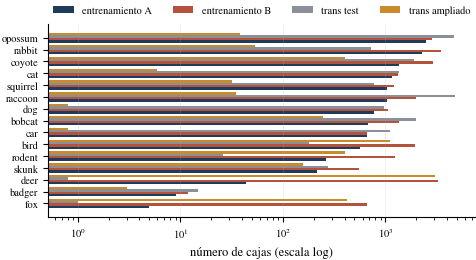

In [13]:
YOLO_DIR = f'{LOCAL}/yolo'
def usables(M): return M[M.estado != 'animal_sin_caja']
CONJ = {'train_A': IMGS[IMGS.image_id.isin(set(SEL['train_A']))],
        'val': usables(IMGS[IMGS.split.isin(['cis_val', 'trans_val'])]),
        'cis_test': usables(IMGS[IMGS.split == 'cis_test']),
        'trans_test': usables(IMGS[IMGS.split == 'trans_test']),
        'trans_ext': IMGS[IMGS.image_id.isin(set(SEL['trans_ext']))]}
if 'B' in CFG['modelos']:
    CONJ['train_B'] = pd.concat([CONJ['train_A'], IMGS[IMGS.image_id.isin(set(SEL['ext_train']))]])
for k in CONJ: CONJ[k] = CONJ[k].reset_index(drop=True)
# pesos de Horvitz-Thompson por imagen (solo las vacías del trans ampliado pesan k)
W0 = {k: np.ones(len(I), int) for k, I in CONJ.items()}
W0['trans_ext'] = np.where(CONJ['trans_ext'].estado == 'vacia', CFG['k_vacias_ext'], 1)

def escribir_yolo(nombre, I):
    di = f'{YOLO_DIR}/images/{nombre}'; dl = f'{YOLO_DIR}/labels/{nombre}'
    for d in (di, dl): shutil.rmtree(d, ignore_errors=True); Path(d).mkdir(parents=True)
    g = {k: v for k, v in CAJAS[CAJAS.cls >= 0].groupby('image_id')}
    for r in I.itertuples():
        os.symlink(r.ruta, f'{di}/{r.image_id}.jpg')
        with open(f'{dl}/{r.image_id}.txt', 'w') as f:
            for c in (g[r.image_id].itertuples() if r.image_id in g else []):
                f.write(f'{c.cls} {(c.x1 + c.x2) / 2:.6f} {(c.y1 + c.y2) / 2:.6f} {c.x2 - c.x1:.6f} {c.y2 - c.y1:.6f}\n')

def escribir_yaml(nombre, train, val):
    p = f'{YOLO_DIR}/{nombre}.yaml'
    with open(p, 'w') as f:
        f.write(f'path: {YOLO_DIR}\ntrain: images/{train}\nval: images/{val}\nnames:\n')
        for i, c in enumerate(CLASES): f.write(f'  {i}: {c}\n')
    return p

if not os.path.exists(f'{YOLO_DIR}/.listo'):
    for k, I in CONJ.items(): escribir_yolo(k, I)
    Path(f'{YOLO_DIR}/.listo').touch()
YAML = {m: escribir_yaml(f'cct_{m}', f'train_{m}', 'val') for m in CFG['modelos']}
YAML_EVAL = {sp: escribir_yaml(f'eval_{sp}', 'train_A', sp) for sp in ['cis_test', 'trans_test']}

filas = []
for m in CFG['modelos']:
    I = CONJ[f'train_{m}']; C = CAJAS[CAJAS.image_id.isin(set(I.image_id)) & (CAJAS.cls >= 0)]
    filas.append([m, str(I.location.nunique()), num(len(I)), pct((I.estado == 'vacia').mean()), num(len(C))])
    macro(f'nTrain{m}', num(len(I))); macro(f'nCajasTrain{m}', num(len(C))); macro(f'nUbicTrain{m}', I.location.nunique())
    macro(f'pctFondoTrain{m}', pct((I.estado == 'vacia').mean()))
tabla_tex(filas, ['Modelo', 'Cámaras', 'Imágenes', r'\% fondo', 'Cajas'], 'tab_entrenamiento')
for k, I in CONJ.items(): print(f'{k:11s} imágenes {len(I):6d} | vacías {100 * (I.estado == "vacia").mean():5.1f} % | cámaras {I.location.nunique()}')
macro('nVal', num(len(CONJ['val']))); macro('nCisTest', num(len(CONJ['cis_test']))); macro('nTransTest', num(len(CONJ['trans_test'])))
macro('nTransExt', num(len(CONJ['trans_ext']))); macro('nCajasTransExt', num(CAJAS[CAJAS.image_id.isin(set(CONJ['trans_ext'].image_id))].shape[0]))
macro('pctVaciasExtPond', pct(np.sum(W0['trans_ext'] * (CONJ['trans_ext'].estado == 'vacia')) / W0['trans_ext'].sum()))

# distribución de cajas por especie
fig, ax = plt.subplots(figsize=(ANCHO, 2.5))
orden = CLASES[::-1]; y = np.arange(len(orden)); hgt = .2
series = [('train_A', COL['A'], 'entrenamiento A'), ('train_B', COL['B'], 'entrenamiento B'),
          ('trans_test', COL['gris'], 'trans test'), ('trans_ext', COL['trans_ext'], 'trans ampliado')]
series = [s for s in series if s[0] in CONJ]
for k, (sp, c, lab) in enumerate(series):
    v = CAJAS[CAJAS.image_id.isin(set(CONJ[sp].image_id))].cat.value_counts().reindex(orden).fillna(0).values
    ax.barh(y + (k - (len(series) - 1) / 2) * hgt, np.maximum(v, .8), height=hgt, color=c, label=lab)
ax.set_xscale('log'); ax.set_yticks(y); ax.set_yticklabels(orden); ax.set_xlabel('número de cajas (escala log)')
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(.5, 1.0), ncol=4); ax.grid(axis='y', alpha=0)
guardar_fig(fig, 'fig_distribucion_clases')

**Composición resultante.** B duplica las cajas de entrenamiento (24 573 frente a 12 617) y pasa de 10 a 56 cámaras. El cambio más
fuerte está en las especies raras: el ciervo pasa de 44 a 3 276 cajas y el zorro de 5 a 669, como muestra la figura. En el trans ampliado, la
mitad de las cajas es de ciervo, y esto debe tenerse en cuenta al interpretar sus métricas.

## 5. Entrenamiento reanudable de A y B (entregable 1)

| Decisión | Valor | Justificación |
|---|---|---|
| Modelo | YOLOv8-s, pesos COCO | Recomendado por el enunciado; cabe en una T4 con lote 16 a 640 px |
| Resolución | 640 px | Resolución de preentrenamiento; su costo en objetos pequeños se mide en el entregable 4 |
| Color | `hsv_h=0`, `hsv_s=0.4`, `hsv_v=0.4` | Las capturas nocturnas son infrarrojas y monocromas, por lo que el tono no tiene significado físico |
| Geometría | `fliplr=0.5`, `flipud=0`, `degrees=0`, `scale=0.5`, `translate=0.1` | Cámara fija y orientación gravitatoria |
| Mosaico | 1.0, desactivado en las 10 últimas épocas | Diversifica el contexto de cada animal frente al atajo de fondo |
| `mixup`, `copy_paste` | 0 | Producirían escenas físicamente implausibles |
| Fondo | 10 % objetivo; B replica la fracción de A | El `train` oficial no tiene vacías, así que ambos modelos se entrenaron con fracción 0 |
| Optimización | SGD, `lr0=0.01`, momento 0.937, `wd=5e-4` | Valores por defecto de YOLOv8 para ajuste fino |

**Tratamiento del fondo.** Sin imágenes vacías, la supervisión del fondo procede de las regiones sin animal de cada imagen con fauna.
Con a lo sumo 10 candidatos positivos por objeto (asignación TAL) y unas 1.04 cajas por imagen, más del 99.8 % de los 8 400
candidatos de cada imagen se entrenan como fondo. Lo que falta no es supervisión negativa sino diversidad de escenas vacías; su efecto
se mide en la evaluación con la tasa de falsos positivos en vacías y el AUROC entre vacía y fauna.

A y B comparten hiperparámetros, semilla, número máximo de épocas y validación. Cada entrenamiento escribe `last.pt` en Drive al final de
cada época, y un *callback* guarda una copia verificada que reemplaza a `last.pt` si este quedó corrupto por una desconexión.

In [14]:
HIP = dict(optimizer='SGD', lr0=0.01, lrf=0.01, momentum=0.937, weight_decay=5e-4, warmup_epochs=3,
           close_mosaic=min(10, CFG['epochs']), mosaic=1.0, mixup=0.0, copy_paste=0.0, degrees=0.0, translate=0.1,
           scale=0.5, shear=0.0, perspective=0.0, fliplr=0.5, flipud=0.0, hsv_h=0.0, hsv_s=0.4, hsv_v=0.4, box=7.5, cls=0.5, dfl=1.5)
def run_dir(m): return f'{RUNS}/yolov8s_{m}_{S}'
BEST = {m: f'{WORK}/modelos/best_{m}_{S}.pt' for m in CFG['modelos']}

def ckpt_valido(p):
    try: return torch.load(p, map_location='cpu', weights_only=False)
    except Exception as e: print('checkpoint ilegible:', p, e); return None

def entrenar(m):
    last = f'{run_dir(m)}/weights/last.pt'; resp = f'{WORK}/ckpt/last_backup_{m}.pt'
    if hecho(f'entrenamiento_{m}'): print(m, 'ya entrenado'); return
    def cb_respaldo(tr):
        try:
            if ckpt_valido(tr.last) is not None: shutil.copy(tr.last, resp + '.tmp'); os.replace(resp + '.tmp', resp)
        except Exception as e: print('respaldo fallido:', e)
    def cb_caida(tr):
        ep = CFG.get('simular_caida_en_epoca')
        if ep is not None and m == CFG['modelos'][0] and tr.epoch + 1 >= ep and not os.path.exists(f'{ESTADO}/caida_simulada'):
            Path(f'{ESTADO}/caida_simulada').touch(); raise RuntimeError('Caída simulada para probar la reanudación')
    terminado = False
    if os.path.exists(last):
        ck = ckpt_valido(last)
        if ck is None and os.path.exists(resp): print('Restaurando respaldo'); shutil.copy(resp, last); ck = ckpt_valido(last)
        terminado = ck is not None and ck.get('epoch', -1) == -1
    t0 = time.time()
    if not terminado:
        if os.path.exists(last):
            print(m, ': reanudando desde', last); y = YOLO(last)
            y.add_callback('on_model_save', cb_respaldo); y.add_callback('on_fit_epoch_end', cb_caida); y.train(resume=True)
        else:
            y = YOLO(CFG['modelo']); y.add_callback('on_model_save', cb_respaldo); y.add_callback('on_fit_epoch_end', cb_caida)
            y.train(data=YAML[m], imgsz=S, epochs=CFG['epochs'], patience=CFG['patience'], batch=CFG['batch'], workers=CFG['workers'],
                    seed=CFG['seed'], project=RUNS, name=os.path.basename(run_dir(m)), exist_ok=True, cache=False,
                    plots=not MODO_PRUEBA, device=0 if DEV != 'cpu' else 'cpu', **HIP)
    shutil.copy(f'{run_dir(m)}/weights/best.pt', BEST[m])
    rc = pd.read_csv(f'{run_dir(m)}/results.csv'); rc.columns = [c.strip() for c in rc.columns]
    marcar(f'entrenamiento_{m}', dict(epocas=int(rc.epoch.max()), tiempo_s=float(rc['time'].max()) if 'time' in rc else None,
                                      sesion_min=(time.time() - t0) / 60))

for m in CFG['modelos']: entrenar(m)
print({m: leer_marca(f'entrenamiento_{m}') for m in CFG['modelos']})

A ya entrenado
B ya entrenado
{'A': {'epocas': 37, 'tiempo_s': 9513.92, 'sesion_min': 159.92744396924974}, 'B': {'epocas': 45, 'tiempo_s': 7842.08, 'sesion_min': 120.28856336673101}}


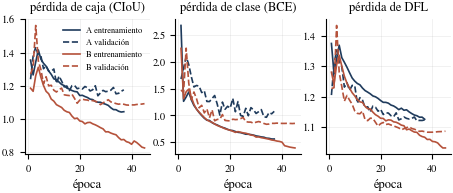

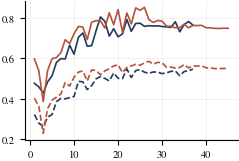

In [15]:
# ---------- curvas y metadatos de los modelos ----------
fig, ax = plt.subplots(1, 3, figsize=(ANCHO, 1.75))
fig2, ax2 = plt.subplots(figsize=(ANCHO / 2, 1.8))
for m in CFG['modelos']:
    rc = pd.read_csv(f'{run_dir(m)}/results.csv'); rc.columns = [c.strip() for c in rc.columns]
    for k, (nom, c) in enumerate([('caja (CIoU)', 'box_loss'), ('clase (BCE)', 'cls_loss'), ('DFL', 'dfl_loss')]):
        ax[k].plot(rc.epoch, rc[f'train/{c}'], color=COL[m], label=f'{m} entrenamiento')
        ax[k].plot(rc.epoch, rc[f'val/{c}'], color=COL[m], ls='--', label=f'{m} validación'); ax[k].set_title(f'pérdida de {nom}'); ax[k].set_xlabel('época')
    ax2.plot(rc.epoch, rc['metrics/mAP50(B)'], color=COL[m], label=f'{m}: mAP@0.5')
    ax2.plot(rc.epoch, rc['metrics/mAP50-95(B)'], color=COL[m], ls='--', label=f'{m}: mAP@0.5:0.95')
    info = leer_marca(f'entrenamiento_{m}')
    macro(f'epocasReal{m}', info['epocas']); macro(f'mejorEpoca{m}', int(rc.loc[rc['metrics/mAP50-95(B)'].idxmax(), 'epoch']))
    if info.get('tiempo_s'): macro(f'horasEntrenamiento{m}', f'{info["tiempo_s"] / 3600:.1f}')
ax[0].legend(frameon=False, fontsize=6); guardar_fig(fig, 'fig_perdidas')
ax2.set_xlabel('época'); ax2.set_ylabel('validación'); ax2.legend(frameon=False, fontsize=6); guardar_fig(fig2, 'fig_map_validacion')
mdl = YOLO(BEST[CFG['modelos'][0]])
macro('nParams', f'{sum(p.numel() for p in mdl.model.parameters()) / 1e6:.1f}')
try:
    from ultralytics.utils.torch_utils import get_flops; macro('gflops', f'{get_flops(mdl.model, S):.1f}')
except Exception: pass
macro('imgsz', S); macro('fracFondo', pct(CFG['frac_fondo'], 0))

**Entrenamiento.** La parada temprana detuvo A en la época 37 (mejor época 22) y B en la 45 (mejor época 27). B alcanza pérdidas de
validación menores en los tres términos, CIoU, BCE y DFL, y un mAP de validación más alto en casi todas las épocas. Ambos modelos
alcanzan su mejor época mucho antes del máximo de 50, lo que confirma la utilidad de la parada temprana.

## 6. Inferencia por bloques reanudables

Las predicciones se generan con puntuación mínima de 0.001, NMS por clase con IoU 0.7 y hasta 100 detecciones por imagen, que es el
protocolo de evaluación de COCO. Se guardan en Drive por modelo, conjunto y bloque de 2000 imágenes.

Cada llamada a `predict` recibe solo 32 rutas: con una lista de rutas, Ultralytics 8.3 arma un único lote con toda la lista, y un bloque
de 2000 imágenes llegó a pedir 12 GiB de memoria de video.

In [16]:
def inferir(m, nombre, rutas, ids):
    """Inferencia por bloques reanudables. Cada predict recibe solo batch_inf rutas: con una lista de rutas,
    Ultralytics 8.3 arma un único lote con toda la lista (con 2000 imágenes pediría ~12 GiB de VRAM)."""
    d = f'{PRED}/{m}/{nombre}'; Path(d).mkdir(parents=True, exist_ok=True); y = None; partes = []; bi = CFG['batch_inf']
    for b in range(0, len(rutas), CFG['chunk']):
        f = f'{d}/bloque_{b // CFG["chunk"]:04d}.parquet'
        if not os.path.exists(f):
            if y is None: y = YOLO(BEST[m])
            filas = []
            for k in range(b, min(b + CFG['chunk'], len(rutas)), bi):
                res = y.predict(source=rutas[k:k + bi], imgsz=S, conf=CFG['conf_eval'], iou=CFG['iou_nms'], max_det=CFG['max_det'],
                                half=DEV != 'cpu', verbose=False, device=DEV)
                for iid, r in zip(ids[k:k + bi], res):
                    bx = r.boxes
                    if len(bx):
                        xy = bx.xyxyn.cpu().numpy(); sc = bx.conf.cpu().numpy(); cl = bx.cls.cpu().numpy().astype(int)
                        filas += [(iid, cl[j], float(sc[j]), *map(float, xy[j])) for j in range(len(sc))]
            pd.DataFrame(filas, columns=['image_id', 'cls', 'score', 'x1', 'y1', 'x2', 'y2']).to_parquet(f + '.tmp'); os.replace(f + '.tmp', f)
        partes.append(pd.read_parquet(f))
    out = pd.concat(partes, ignore_index=True); out['image_id'] = out.image_id.astype(str); return out

import gc; gc.collect()
if DEV != 'cpu': torch.cuda.empty_cache()

EVALS = ['val', 'cis_test', 'trans_test', 'trans_ext']
DET = {m: {} for m in CFG['modelos']}
for m in CFG['modelos']:
    for sp in EVALS:
        I = CONJ[sp]; t0 = time.time(); DET[m][sp] = inferir(m, sp, I.ruta.tolist(), I.image_id.tolist())
        print(f'{m} {sp}: {len(DET[m][sp])} detecciones en {len(I)} imágenes ({time.time() - t0:.0f} s)')

A val: 54151 detecciones en 4254 imágenes (59 s)
A cis_test: 150021 detecciones en 13876 imágenes (175 s)
A trans_test: 259106 detecciones en 19811 imágenes (253 s)
A trans_ext: 157542 detecciones en 11629 imágenes (145 s)
B val: 31783 detecciones en 4254 imágenes (57 s)
B cis_test: 84270 detecciones en 13876 imágenes (178 s)
B trans_test: 156267 detecciones en 19811 imágenes (251 s)
B trans_ext: 136465 detecciones en 11629 imágenes (142 s)


## 7. Evaluador propio tipo COCO

El evaluador reproduce el protocolo de `pycocotools`: emparejamiento voraz por puntuación, prioridad de las verdades de terreno no
ignoradas, 101 puntos de recall y umbrales de IoU de 0.50 a 0.95. Además añade dos operaciones que los análisis necesitan:

* ignorar las cajas fuera de un subgrupo, para los análisis de oclusión y tamaño;
* acumular con pesos enteros por imagen, para el *bootstrap* por cámara y para la ponderación de Horvitz-Thompson.

In [17]:
IOU_T = np.round(np.linspace(0.5, 0.95, 10), 2); REC_T = np.linspace(0, 1, 101)

def iou_mat(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(aa[:, None] + ab[None, :] - inter, 1e-12)

def emparejar(gt, dt, img_ids, gt_ign=None, dt_fuera=None, max_det=100):
    """gt_ign, dt_fuera: funciones sobre el DataFrame filtrado que devuelven máscaras booleanas."""
    pos = {iid: i for i, iid in enumerate(img_ids)}
    gt = gt[gt.image_id.isin(pos)].reset_index(drop=True); dt = dt[dt.image_id.isin(pos)].reset_index(drop=True)
    G = gt[['x1', 'y1', 'x2', 'y2']].values; D = dt[['x1', 'y1', 'x2', 'y2']].values
    gc = gt.cls.values; dc = dt.cls.values; ds = dt.score.values
    gign = (np.zeros(len(gt), bool) if gt_ign is None else np.asarray(gt_ign(gt), bool)) | (gc < 0)
    dfu = np.zeros(len(dt), bool) if dt_fuera is None else np.asarray(dt_fuera(dt), bool)
    gimg = gt.image_id.map(pos).values; dimg = dt.image_id.map(pos).values
    gidx = pd.Series(np.arange(len(gt))).groupby([gimg, gc]).indices if len(gt) else {}
    didx = pd.Series(np.arange(len(dt))).groupby([dimg, dc]).indices if len(dt) else {}
    T = len(IOU_T); d_keep = np.zeros(len(dt), bool); d_m = np.zeros((T, len(dt)), bool); d_ig = np.zeros((T, len(dt)), bool)
    g_ms = np.zeros((T, len(gt)))
    for key in sorted(set(gidx) | set(didx)):
        di = didx.get(key, np.array([], int)); gi = gidx.get(key, np.array([], int))
        if len(di): di = di[np.argsort(-ds[di], kind='mergesort')][:max_det]; d_keep[di] = True
        if len(di) == 0: continue
        if len(gi) == 0: d_ig[:, di] = dfu[di][None, :]; continue
        gi = gi[np.argsort(gign[gi], kind='mergesort')]; ious = iou_mat(D[di], G[gi]); gig = gign[gi]
        for t, thr0 in enumerate(IOU_T):
            gtm = np.full(len(gi), -1)
            if len(gi) == 1:
                ok = np.nonzero(ious[:, 0] >= min(thr0, 1 - 1e-10))[0]
                if len(ok): d0 = ok[0]; d_m[t, di[d0]] = True; d_ig[t, di[d0]] = gig[0]; g_ms[t, gi[0]] = ds[di[d0]]
            else:
                for dd in range(len(di)):
                    thr = min(thr0, 1 - 1e-10); mm = -1
                    for g in range(len(gi)):
                        if gtm[g] >= 0: continue
                        if mm > -1 and not gig[mm] and gig[g]: break
                        if ious[dd, g] < thr: continue
                        thr = ious[dd, g]; mm = g
                    if mm == -1: continue
                    gtm[mm] = dd; d_m[t, di[dd]] = True; d_ig[t, di[dd]] = gig[mm]; g_ms[t, gi[mm]] = ds[di[dd]]
            d_ig[t, di] |= (~d_m[t, di]) & dfu[di]
    k = np.nonzero(d_keep)[0]; k = k[np.lexsort((-ds[k], dimg[k]))]
    return dict(n_img=len(img_ids), d_img=dimg[k], d_cls=dc[k], d_score=ds[k], d_m=d_m[:, k], d_ig=d_ig[:, k],
                g_img=gimg, g_cls=gc, g_ign=gign, g_ms=g_ms, gt=gt, dt=dt.iloc[k].reset_index(drop=True))

def acumular(R, w=None, clases=None):
    """AP[T, K] y recall[T, K] con pesos enteros por imagen."""
    w = np.ones(R['n_img'], int) if w is None else np.asarray(w, int)
    clases = range(NC) if clases is None else clases
    AP = np.full((len(IOU_T), NC), np.nan); RC = np.full((len(IOU_T), NC), np.nan); rep = w[R['d_img']]
    for kk in clases:
        npos = (w[R['g_img']] * ((R['g_cls'] == kk) & ~R['g_ign'])).sum()
        if npos == 0: continue
        idx = np.nonzero((R['d_cls'] == kk) & (rep > 0))[0]; idx = np.repeat(idx, rep[idx])
        idx = idx[np.argsort(-R['d_score'][idx], kind='mergesort')]
        mm = R['d_m'][:, idx]; ig = R['d_ig'][:, idx]; tpc = np.cumsum(mm & ~ig, 1); fpc = np.cumsum(~mm & ~ig, 1)
        for t in range(len(IOU_T)):
            if len(idx) == 0: AP[t, kk] = 0; RC[t, kk] = 0; continue
            rc = tpc[t] / npos; pr = tpc[t] / (tpc[t] + fpc[t] + np.spacing(1)); pr = np.maximum.accumulate(pr[::-1])[::-1]
            ii = np.searchsorted(rc, REC_T, side='left'); q = np.zeros(len(REC_T)); v = ii < len(rc); q[v] = pr[ii[v]]
            AP[t, kk] = q.mean(); RC[t, kk] = rc[-1]
    return AP, RC

def resumen(AP):
    return dict(map50=np.nanmean(AP[0]), map=np.nanmean(np.nanmean(AP, 0)), ap50=AP[0], ap=np.nanmean(AP, 0))

def gt_de(I):
    return CAJAS[CAJAS.image_id.isin(set(I.image_id))][['image_id', 'cls', 'x1', 'y1', 'x2', 'y2', 'cat', 'location']].reset_index(drop=True)

In [18]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib

def map_pycocotools(gt, dt, img_ids):
    gt = gt[gt.cls >= 0]; pos = {iid: i for i, iid in enumerate(img_ids)}
    im = [{'id': i, 'width': 1000, 'height': 1000} for i in range(len(img_ids))]
    an = [{'id': j + 1, 'image_id': pos[r.image_id], 'category_id': int(r.cls), 'iscrowd': 0,
           'bbox': [1000 * r.x1, 1000 * r.y1, 1000 * (r.x2 - r.x1), 1000 * (r.y2 - r.y1)], 'area': 1e6 * (r.x2 - r.x1) * (r.y2 - r.y1)}
          for j, r in enumerate(gt.itertuples())]
    C = COCO(); C.dataset = {'images': im, 'annotations': an, 'categories': [{'id': i} for i in range(NC)]}
    with contextlib.redirect_stdout(io.StringIO()): C.createIndex()
    d = dt[dt.image_id.isin(pos)]
    res = [{'image_id': pos[r.image_id], 'category_id': int(r.cls), 'score': float(r.score),
            'bbox': [1000 * r.x1, 1000 * r.y1, 1000 * (r.x2 - r.x1), 1000 * (r.y2 - r.y1)]} for r in d.itertuples()]
    with contextlib.redirect_stdout(io.StringIO()):
        E = COCOeval(C, C.loadRes(res), 'bbox'); E.params.maxDets = [1, 10, 100]; E.evaluate(); E.accumulate(); E.summarize()
    return E.stats[0], E.stats[1]

R = {m: {} for m in CFG['modelos']}
for m in CFG['modelos']:
    for sp in EVALS: R[m][sp] = emparejar(gt_de(CONJ[sp]), DET[m][sp], CONJ[sp].image_id.tolist())

ver = []
for m in CFG['modelos']:
    for sp in ['cis_test', 'trans_test']:
        I = CONJ[sp]; s = resumen(acumular(R[m][sp])[0]); p = map_pycocotools(gt_de(I), DET[m][sp], I.image_id.tolist())
        if hecho(f'val_ultra_{m}_{sp}'): u = leer_marca(f'val_ultra_{m}_{sp}')
        else:
            r = YOLO(BEST[m]).val(data=YAML_EVAL[sp], split='val', imgsz=S, batch=CFG['batch_inf'], conf=CFG['conf_eval'], iou=CFG['iou_nms'],
                                 plots=False, project=f'{WORK}/val', name=f'{m}_{sp}', exist_ok=True, device=DEV, verbose=False)
            u = dict(map50=float(r.box.map50), map=float(r.box.map)); marcar(f'val_ultra_{m}_{sp}', u)
        ver.append([f'{m}, {NOMDOM[sp]}', pct(s['map50']), pct(p[1]), pct(u['map50']), pct(s['map']), pct(p[0]), pct(u['map'])])
        print(m, sp, 'propio', s['map50'], s['map'], '| pycocotools', p[1], p[0], '| ultralytics', u['map50'], u['map'])
grp = r' & \multicolumn{3}{c}{mAP@0.5 (\%)} & \multicolumn{3}{c}{mAP@0.5:0.95 (\%)} \\ \cmidrule(lr){2-4}\cmidrule(lr){5-7}'
tabla_tex(ver, ['Modelo y dominio', 'propio', 'pycoco', 'Ultralytics', 'propio', 'pycoco', 'Ultralytics'], 'tab_verificacion', grupos=grp)

Ultralytics 8.3.253 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,131,389 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 320.6±572.2 MB/s, size: 70.9 KB)
val: Scanning /content/p3/yolo/labels/cis_test... 13876 images, 1180 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 13876/13876 562.0it/s 24.7s
val: New cache created: /content/p3/yolo/labels/cis_test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 434/434 2.8it/s 2:33
                   all      13876      13264      0.843       0.64      0.694      0.462
Speed: 0.6ms preprocess, 8.5ms inference, 0.0ms loss, 0.7ms postprocess per image
A cis_test propio 0.6662597988151158 0.43991148055297785 | pycocotools 0.6662597988151157 0.43991148055297785 | ultralytics 0.6937958537787405 0.461909146606559
Ultralytics 8.3.253 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Mode

**Verificación del evaluador.** El evaluador propio coincide con `pycocotools` hasta la última cifra en los cuatro casos. El `val()` de
Ultralytics da entre 1.8 y 3.2 puntos más, porque interpola la curva precisión-recall y empareja de otra forma; el informe reporta el
protocolo COCO.

## 8. Umbral de operación y tratamiento de las vacías

Para cada modelo, el umbral de operación $\tau^\ast$ se elige en validación maximizando $F_2$, que pondera el recall cuatro veces más que
la precisión. La razón, desarrollada en la discusión del informe (entregable 6), es la asimetría de costos: un falso negativo puede excluir
una especie amenazada de las decisiones de manejo, mientras que un falso positivo solo consume tiempo de revisión.

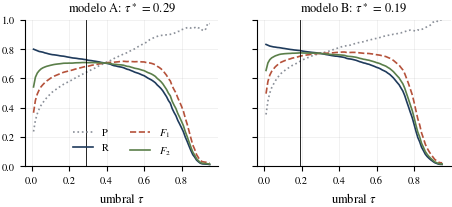

tau*: {'A': 0.29000000000000004, 'B': 0.19}
                  A                             B                     
           cis_test trans_test trans_ext cis_test trans_test trans_ext
auc           0.963      0.865     0.712    0.917      0.922     0.879
fpr_vacias    0.140      0.367     0.349    0.305      0.308     0.218
tpr           0.945      0.903     0.712    0.972      0.937     0.816


In [19]:
MODS = list(CFG['modelos'])
def curva_umbral(Rx, grid=np.linspace(0.01, 0.95, 95)):
    mm = Rx['d_m'][0]; ig = Rx['d_ig'][0]; s = Rx['d_score']; npos = (~Rx['g_ign']).sum(); out = []
    for t in grid:
        k = s >= t; tp = (mm & ~ig & k).sum(); fp = (~mm & ~ig & k).sum(); P = tp / max(tp + fp, 1); Rr = tp / max(npos, 1)
        out.append((t, P, Rr, 2 * P * Rr / max(P + Rr, 1e-9), 5 * P * Rr / max(4 * P + Rr, 1e-9)))
    return pd.DataFrame(out, columns=['tau', 'P', 'R', 'F1', 'F2'])

TAU, TAU1 = {}, {}
fig, ax = plt.subplots(1, len(MODS), figsize=(ANCHO, 1.9), sharey=True, squeeze=False); ax = ax[0]
for j, m in enumerate(MODS):
    CU = curva_umbral(R[m]['val']); TAU[m] = float(CU.loc[CU.F2.idxmax(), 'tau']); TAU1[m] = float(CU.loc[CU.F1.idxmax(), 'tau'])
    for c, col, ls in [('P', COL['gris'], ':'), ('R', COL['cis'], '-'), ('F1', COL['trans'], '--'), ('F2', COL['ena24'], '-')]:
        ax[j].plot(CU.tau, CU[c], color=col, ls=ls, label=c if c in ('P', 'R') else f'$F_{c[1]}$')
    ax[j].axvline(TAU[m], color='k', lw=.6); ax[j].set_title(f'modelo {m}: $\\tau^\\ast$ = {TAU[m]:.2f}'); ax[j].set_xlabel(r'umbral $\tau$')
    f = CU.loc[CU.F2.idxmax()]
    macro(f'tauFdos{m}', f'{TAU[m]:.2f}'); macro(f'tauFuno{m}', f'{TAU1[m]:.2f}'); macro(f'precTau{m}', pct(f.P)); macro(f'recTau{m}', pct(f.R))
ax[0].legend(frameon=False, ncol=2); ax[0].set_ylim(0, 1); guardar_fig(fig, 'fig_umbral')
print('tau*:', TAU)

def nivel_imagen(m, sp):
    I = CONJ[sp]; w = W0[sp]
    smax = DET[m][sp].groupby('image_id').score.max().reindex(I.image_id).fillna(0).values; y = (I.estado == 'animal_con_caja').values
    auc = roc_auc_score(y, smax, sample_weight=w) if 0 < y.mean() < 1 else np.nan
    return dict(auc=auc, fpr_vacias=(smax[~y] >= TAU[m]).mean() if (~y).any() else np.nan, tpr=(smax[y] >= TAU[m]).mean())
NIV = {m: {sp: nivel_imagen(m, sp) for sp in ['cis_test', 'trans_test', 'trans_ext']} for m in MODS}
print(pd.DataFrame({(m, sp): v for m in MODS for sp, v in NIV[m].items()}).round(3))

**Umbrales y vacías.** El criterio $F_2$ fija $\tau^\ast_A = 0.29$ y $\tau^\ast_B = 0.19$, por debajo de los umbrales de $F_1$ (0.49 y 0.42).
En validación, B opera con un recall de 79.0 % y una precisión de 71.5 %.

La separabilidad entre vacías y fauna es la señal más clara de dependencia del contexto:

* **A:** el AUROC cae de 0.963 en cis a 0.865 en trans y 0.712 en el trans ampliado, y al mismo umbral la tasa de falsos positivos en vacías pasa de 14.0 % a 36.7 %.
* **B:** mantiene el AUROC entre 0.879 y 0.922 en los tres dominios.

## 9. Evaluación por especie (entregable 2)

Se calcula el AP@0.5 y el AP@0.5:0.95 por especie en cada dominio y para cada modelo. El efecto del desbalance se cuantifica con la
correlación de Spearman entre el AP y $\log_{10}$ del número de cajas de entrenamiento de cada especie. Al pasar de A a B cambian a la vez
el número de cajas de las especies raras y la diversidad de cámaras.

A cis_test   mAP@0.5 = 66.6  mAP@0.5:0.95 = 44.0
A trans_test mAP@0.5 = 40.6  mAP@0.5:0.95 = 27.8
A trans_ext  mAP@0.5 = 21.0  mAP@0.5:0.95 = 13.1
B cis_test   mAP@0.5 = 73.5  mAP@0.5:0.95 = 50.8
B trans_test mAP@0.5 = 48.5  mAP@0.5:0.95 = 31.1
B trans_ext  mAP@0.5 = 51.7  mAP@0.5:0.95 = 43.0
Spearman: {('A', 'cis_test'): (np.float64(0.6344953382574064), np.float64(0.011061646723750766)), ('A', 'trans_test'): (np.float64(0.5632566664711138), np.float64(0.03595996717962155)), ('A', 'trans_ext'): (np.float64(0.5419537451625185), np.float64(0.05572229487253864)), ('B', 'cis_test'): (np.float64(0.1928571428571428), np.float64(0.4910487016052232)), ('B', 'trans_test'): (np.float64(0.36303652331146014), np.float64(0.20203106958329903)), ('B', 'trans_ext'): (np.float64(-0.03846153846153846), np.float64(0.9007243023389337))}


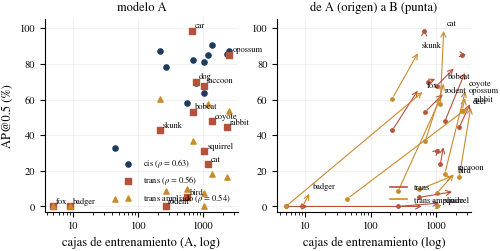

In [20]:
DOMS = ['cis_test', 'trans_test', 'trans_ext']
RES_AP = {m: {sp: resumen(acumular(R[m][sp], W0[sp])[0]) for sp in DOMS} for m in MODS}
N_TRAIN = {m: CAJAS[CAJAS.image_id.isin(set(CONJ[f'train_{m}'].image_id)) & (CAJAS.cls >= 0)].cls.value_counts().reindex(range(NC)).fillna(0).astype(int).values
           for m in MODS}
for m in MODS:
    for sp in DOMS:
        s = RES_AP[m][sp]; macro(f'map{SUF[sp]}Cinc{m}', pct(s['map50'])); macro(f'map{SUF[sp]}Coco{m}', pct(s['map']))
        print(f'{m} {sp:10s} mAP@0.5 = {100 * s["map50"]:.1f}  mAP@0.5:0.95 = {100 * s["map"]:.1f}')

SP = {}
for m in MODS:
    med = np.median(N_TRAIN[m][N_TRAIN[m] > 0]); cab = N_TRAIN[m] >= med
    for sp in DOMS:
        a = RES_AP[m][sp]['ap50']; ok = np.isfinite(a) & (N_TRAIN[m] > 0)
        r = stats.spearmanr(np.log10(N_TRAIN[m][ok]), a[ok]) if ok.sum() > 2 else None
        SP[(m, sp)] = (r.correlation, r.pvalue) if r is not None else (np.nan, np.nan)
        macro(f'rho{SUF[sp]}{m}', f'{SP[(m, sp)][0]:.2f}'); macro(f'p{SUF[sp]}{m}', f'{SP[(m, sp)][1]:.3f}')
        macro(f'apCabeza{SUF[sp]}{m}', pct(np.nanmean(a[cab]))); macro(f'apCola{SUF[sp]}{m}', pct(np.nanmean(a[~cab])))
    macro(f'medianaCajas{m}', num(med))
print('Spearman:', SP)

fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.5))
m0 = MODS[0]
for sp, c, mk in [('cis_test', COL['cis'], 'o'), ('trans_test', COL['trans'], 's'), ('trans_ext', COL['trans_ext'], '^')]:
    a = RES_AP[m0][sp]['ap50']; ok = np.isfinite(a) & (N_TRAIN[m0] > 0)
    ax[0].scatter(N_TRAIN[m0][ok], 100 * a[ok], color=c, marker=mk, s=14, label=f'{NOMDOM[sp]} ($\\rho$ = {SP[(m0, sp)][0]:.2f})', zorder=3)
for k in range(NC):
    a = RES_AP[m0]['trans_test']['ap50'][k]
    if np.isfinite(a) and N_TRAIN[m0][k] > 0: ax[0].annotate(CLASES[k], (N_TRAIN[m0][k], 100 * a), xytext=(2, 2), textcoords='offset points', fontsize=6)
ax[0].set_xscale('log'); ax[0].set_xlabel(f'cajas de entrenamiento ({m0}, log)'); ax[0].set_ylabel('AP@0.5 (%)'); ax[0].set_ylim(-3, 105)
ax[0].set_title(f'modelo {m0}'); ax[0].legend(frameon=False, fontsize=6, loc='lower right')
if len(MODS) > 1:
    for k in range(NC):
        for sp, c in [('trans_test', COL['trans']), ('trans_ext', COL['trans_ext'])]:
            a, b = RES_AP['A'][sp]['ap50'][k], RES_AP['B'][sp]['ap50'][k]
            if np.isfinite(a) and np.isfinite(b) and N_TRAIN['A'][k] > 0:
                ax[1].annotate('', (N_TRAIN['B'][k], 100 * b), (N_TRAIN['A'][k], 100 * a), arrowprops=dict(arrowstyle='->', color=c, lw=.8))
                ax[1].scatter([N_TRAIN['A'][k]], [100 * a], color=c, s=6)
        a = RES_AP['B']['trans_ext']['ap50'][k]
        if np.isfinite(a): ax[1].annotate(CLASES[k], (N_TRAIN['B'][k], 100 * a), xytext=(2, 2), textcoords='offset points', fontsize=6)
    ax[1].set_xscale('log'); ax[1].set_xlabel('cajas de entrenamiento (log)'); ax[1].set_ylim(-3, 105)
    ax[1].set_title('de A (origen) a B (punta)')
    from matplotlib.lines import Line2D
    ax[1].legend(handles=[Line2D([], [], color=COL['trans'], label='trans'), Line2D([], [], color=COL['trans_ext'], label='trans ampliado')],
                 frameon=False, fontsize=6, loc='lower right')
for a_ in ax:
    a_.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:g}')); a_.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
guardar_fig(fig, 'fig_ap_vs_instancias')

**Desbalance.** En A, el AP crece con el número de cajas de entrenamiento: $\rho = 0.63$ ($p = 0.011$) en cis y $0.56$ ($p = 0.036$) en
trans. Ciervo, tejón y zorro tienen menos de 50 cajas y obtienen entre 0 y 33 % en cis.

En B la correlación deja de ser significativa ($\rho = 0.19$, $0.36$ y $-0.04$), y la diferencia entre especies frecuentes y raras en trans
baja de 28.4 a 19.1 puntos. Los mayores avances corresponden a las especies que ganaron datos: el ciervo pasa de 32.8 a 65.5 % en cis, y roedor y
zorro superan el 60 % en el trans ampliado. Aves, roedores en trans y ardillas en el trans ampliado siguen por debajo del 10 %: son especies
pequeñas y miméticas, para las que más datos no bastan.

## 10. Brecha entre cámaras vistas y nuevas (entregable 3, parte cuantitativa)

La brecha se mide como $\Delta = \mathrm{mAP}_{\mathrm{cis}} - \mathrm{mAP}_{\mathrm{nuevo}}$ y como incremento relativo del error,
$\Delta_{\mathrm{rel}} = (1-\mathrm{mAP}_{\mathrm{nuevo}})/(1-\mathrm{mAP}_{\mathrm{cis}}) - 1$, la medida que usan Beery et al. (2018).
Las imágenes de una cámara no son independientes, por lo que los intervalos al 95 % se obtienen remuestreando cámaras. En cada réplica se
usan las mismas cámaras para A y para B, lo que da un intervalo pareado para la mejora de B sobre A.

\begin{tabular}{lrrrrrr}
\toprule
Modelo & Dominio nuevo & mAP$_{50}$ cis & mAP$_{50}$ nuevo & $\Delta$ & IC 95\,\% & $\Delta_{\mathrm{rel}}$ (\%) \\
\midrule
A & trans & 66.6 & 40.6 & 26.0 & [16.4, 39.9] & 78 \\
A & trans ampliado & 66.6 & 21.0 & 45.6 & [34.5, 55.8] & 137 \\
B & trans & 73.5 & 48.5 & 25.0 & [13.7, 40.3] & 94 \\
B & trans ampliado & 73.5 & 51.7 & 21.8 & [7.8, 31.1] & 82 \\
\bottomrule
\end{tabular}
mejora B-A en cis_test: 6.9 pts [IC95 1.2, 17.6]
mejora B-A en trans_test: 7.8 pts [IC95 5.2, 12.2]
mejora B-A en trans_ext: 30.7 pts [IC95 23.1, 43.7]


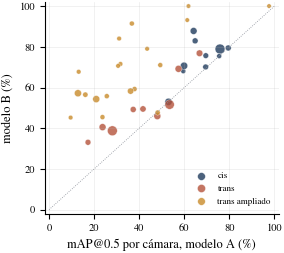

In [21]:
def boot_dom(sp, B, semilla=0):
    f = f'{CACHE}/boot_{sp}_{B}_{"".join(MODS)}.npy'
    if os.path.exists(f): return np.load(f)
    locs = CONJ[sp].location.values; ul = np.unique(locs); por = {l: np.nonzero(locs == l)[0] for l in ul}
    rng_ = np.random.default_rng(semilla); out = np.zeros((B, len(MODS), 2))
    for b in range(B):
        w = np.zeros(len(locs), int)
        for l in rng_.choice(ul, len(ul), replace=True): w[por[l]] += 1
        w = w * W0[sp]
        for j, m in enumerate(MODS):
            AP, _ = acumular(R[m][sp], w); out[b, j] = (np.nanmean(AP[0]), np.nanmean(np.nanmean(AP, 0)))
    np.save(f, out); return out

BT = {sp: boot_dom(sp, CFG['n_boot']) for sp in DOMS}
ic = lambda v: (np.nanpercentile(v, 2.5), np.nanpercentile(v, 97.5))
filas = []
for j, m in enumerate(MODS):
    for sp in DOMS:
        lo, hi = ic(BT[sp][:, j, 0]); macro(f'ic{SUF[sp]}{m}Lo', pct(lo)); macro(f'ic{SUF[sp]}{m}Hi', pct(hi))
    c = RES_AP[m]['cis_test']
    for sp in ['trans_test', 'trans_ext']:
        t = RES_AP[m][sp]; g = c['map50'] - t['map50']; rel = (1 - t['map50']) / (1 - c['map50']) - 1
        lo, hi = ic(BT['cis_test'][:, j, 0] - BT[sp][:, j, 0])   # remuestreos independientes por dominio
        macro(f'brecha{SUF[sp]}{m}', pct(g)); macro(f'brechaCoco{SUF[sp]}{m}', pct(c['map'] - t['map']))
        macro(f'incrError{SUF[sp]}{m}', pct(rel, 0)); macro(f'icBrecha{SUF[sp]}{m}Lo', pct(lo)); macro(f'icBrecha{SUF[sp]}{m}Hi', pct(hi))
        filas.append([m, NOMDOM[sp], pct(c['map50']), pct(t['map50']), pct(g), f'[{pct(lo)}, {pct(hi)}]', pct(rel, 0)])
tabla_tex(filas, ['Modelo', 'Dominio nuevo', r'mAP$_{50}$ cis', r'mAP$_{50}$ nuevo', r'$\Delta$', r'IC 95\,\%', r'$\Delta_{\mathrm{rel}}$ (\%)'], 'tab_brecha')
if len(MODS) > 1:
    for sp in DOMS:
        d = BT[sp][:, 1, 0] - BT[sp][:, 0, 0]; lo, hi = ic(d)
        macro(f'mejora{SUF[sp]}', pct(RES_AP['B'][sp]['map50'] - RES_AP['A'][sp]['map50'])); macro(f'icMejora{SUF[sp]}Lo', pct(lo)); macro(f'icMejora{SUF[sp]}Hi', pct(hi))
        print(f'mejora B-A en {sp}: {100 * (RES_AP["B"][sp]["map50"] - RES_AP["A"][sp]["map50"]):.1f} pts [IC95 {100 * lo:.1f}, {100 * hi:.1f}]')

# mAP@0.5 por cámara: A frente a B
filas = []
for sp in DOMS:
    I = CONJ[sp]; locs = I.location.values
    for l in np.unique(locs):
        w = (locs == l).astype(int) * W0[sp]
        filas.append(dict(dominio=sp, loc=l, n_img=int((locs == l).sum()), **{m: np.nanmean(acumular(R[m][sp], w)[0][0]) for m in MODS}))
UB = pd.DataFrame(filas); UB.to_csv(f'{RES}/map_por_ubicacion.csv', index=False)
fig, ax = plt.subplots(figsize=(ANCHO * .55, ANCHO * .5))
for sp in DOMS:
    u = UB[UB.dominio == sp]; ax.scatter(100 * u[MODS[0]], 100 * u[MODS[-1]], s=10 + u.n_img / u.n_img.max() * 40, color=DOMCOL[sp],
                                         alpha=.8, label=NOMDOM[sp], edgecolor='w', lw=.3)
ax.plot([0, 100], [0, 100], color=COL['gris'], lw=.6, ls=':'); ax.set_xlim(-2, 102); ax.set_ylim(-2, 102)
ax.set_xlabel(f'mAP@0.5 por cámara, modelo {MODS[0]} (%)'); ax.set_ylabel(f'modelo {MODS[-1]} (%)'); ax.legend(frameon=False, fontsize=6.5)
guardar_fig(fig, 'fig_map_por_ubicacion')
for sp in DOMS:
    for m in MODS:
        u = UB[UB.dominio == sp][m]; macro(f'cv{SUF[sp]}{m}', f'{u.std() / u.mean():.2f}' if u.mean() > 0 else '--')

**Brecha.** En A, la brecha frente a trans es de 26.0 puntos (IC 95 % [16.4, 39.9]), es decir, un incremento relativo del error del 78 %,
casi el triple del 28 % de Faster R-CNN en Beery et al. (2018).

B mejora en cis, en trans y en el trans ampliado, y los tres intervalos pareados excluyen el cero:

| Dominio | Mejora B − A | IC 95 % |
|---|---|---|
| cis | +6.9 | [1.2, 17.6] |
| trans | +7.8 | [5.2, 12.2] |
| trans ampliado | +30.7 | [23.1, 43.7] |

Sin embargo, como mejora también en cis, su brecha frente a trans queda en 25.0 puntos. En el trans ampliado la brecha baja de 45.6 a 21.8 puntos, porque esas cámaras se parecen más
a las externas incorporadas en B. El diagrama de dispersión por cámara confirma que la mejora es casi general y que B reduce la variabilidad
entre cámaras: el coeficiente de variación baja de 0.40 a 0.28 en trans.

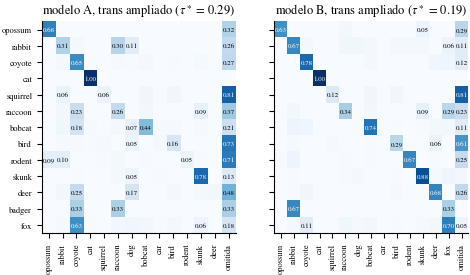

In [22]:
# ---------- descomposición del error al umbral de operación ----------
def descomponer(gt, det, tau):
    d = det[det.score >= tau]; gD = {k: v for k, v in d.groupby('image_id')}; est, pred = [], []
    for r in gt.itertuples():
        if r.cls < 0: est.append('ignorada'); pred.append(-1); continue
        if r.image_id not in gD: est.append('omitida'); pred.append(-1); continue
        v = gD[r.image_id]; iou = iou_mat(np.array([[r.x1, r.y1, r.x2, r.y2]]), v[['x1', 'y1', 'x2', 'y2']].values)[0]; ok = iou >= 0.5
        if (ok & (v.cls.values == r.cls)).any(): est.append('correcta'); pred.append(r.cls)
        elif ok.any(): j = np.argmax(np.where(ok, v.score.values, -1)); est.append('mal_clasificada'); pred.append(int(v.cls.values[j]))
        else: est.append('omitida'); pred.append(-1)
    out = gt.copy(); out['estado_det'] = est; out['pred'] = pred; return out

DESC = {m: {sp: descomponer(R[m][sp]['gt'], DET[m][sp], TAU[m]) for sp in DOMS} for m in MODS}

def panel_confusion(ax, d, titulo, etiquetas_y=True):
    d = d[d.cls >= 0]; pres = sorted(d.cls.unique()); M = np.zeros((len(pres), NC + 1))
    for r in d.itertuples(): M[pres.index(r.cls), NC if r.pred < 0 else r.pred] += 1
    M = M / np.maximum(M.sum(1, keepdims=True), 1); cols = [k for k in range(NC) if M[:, k].sum() > 0] + [NC]
    ax.imshow(M[:, cols], cmap='Blues', vmin=0, vmax=1, aspect='auto'); ax.grid(False)
    ax.set_yticks(range(len(pres))); ax.set_yticklabels([CLASES[k] for k in pres] if etiquetas_y else [], fontsize=6)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels([CLASES[k] if k < NC else 'omitida' for k in cols], rotation=90, fontsize=6)
    for i in range(len(pres)):
        for j, k in enumerate(cols):
            if M[i, k] >= .05: ax.text(j, i, f'{M[i, k]:.2f}', ha='center', va='center', fontsize=5, color='w' if M[i, k] > .55 else 'k')
    ax.set_title(titulo)

def fig_confusion(dom, nombre):
    fig, ax = plt.subplots(1, len(MODS), figsize=(ANCHO, ANCHO * .5), squeeze=False)
    for j, m in enumerate(MODS): panel_confusion(ax[0, j], DESC[m][dom], f'modelo {m}, {NOMDOM[dom]} ($\\tau^\\ast$ = {TAU[m]:.2f})', j == 0)
    guardar_fig(fig, nombre)
fig_confusion('trans_ext', 'fig_confusion_ext')

**Dónde falla el detector.** En trans, A localiza el 85.3 % de los animales (AP agnóstico) pero solo alcanza 40.6 % de mAP por clase.
A $\tau^\ast$, el 15.6 % de las cajas se localiza con la especie equivocada y el 15.3 % se omite. La clasificación es, por tanto, más frágil que la
detección ante el cambio de cámara.

En el trans ampliado, A además deja de localizar (48.2 % de omisiones), y la matriz de confusión muestra que absorbe ciervo, zorro y tejón en
la clase coyote. B corrige la mayor parte de esas confusiones.

## 11. Modelo de fondo por cámara

Como las cámaras son fijas, la mediana píxel a píxel de sus imágenes vacías, separada por modo de captura (color o infrarrojo), estima el
fondo de cada una. Es un instrumento de análisis que no interviene en el entrenamiento. Sirve al contrafactual del entregable 3 y al
estimador de oclusión del entregable 4.

In [23]:
FONDOS = f'{CACHE}/fondos_{S}'; Path(FONDOS).mkdir(exist_ok=True)
def leer_rgb(p): return cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
def modo(img):
    a = img.astype(np.int16); return 'ir' if (np.abs(a[..., 0] - a[..., 1]).mean() + np.abs(a[..., 1] - a[..., 2]).mean()) < 4 else 'color'

if not hecho('fondos'):
    locs_eval = set().union(*[set(CONJ[sp].location) for sp in DOMS])
    for loc, g in IMGS[(IMGS.estado == 'vacia') & IMGS.location.isin(locs_eval)].groupby('location'):
        por = {}
        for r in g.sample(min(len(g), 160), random_state=0).itertuples():
            im = leer_rgb(r.ruta); k = (modo(im), im.shape[0], im.shape[1])
            if len(por.setdefault(k, [])) < 40: por[k].append(im)
        for (mo, h, w), Lst in por.items():
            if len(Lst) >= 5: np.save(f'{FONDOS}/{loc}_{mo}_{h}x{w}.npy', np.median(np.stack(Lst), 0).astype(np.uint8))
    marcar('fondos', {'n': len(os.listdir(FONDOS))})
_cache_f = {}
def fondo(loc, mo, shape):
    for m_ in [mo, 'color' if mo == 'ir' else 'ir']:
        f = f'{FONDOS}/{loc}_{m_}_{shape[0]}x{shape[1]}.npy'
        if os.path.exists(f):
            if f not in _cache_f: _cache_f[f] = np.load(f)
            return _cache_f[f], m_ == mo
    return None, False
print('modelos de fondo:', len(os.listdir(FONDOS)))

modelos de fondo: 47


## 12. ¿Aprende el modelo el fondo? Grad-CAM y contrafactual (entregable 3, parte explicativa)

Se usan tres pruebas complementarias:

* **Grad-CAM.** Para cada caja verdadera de clase $c$ se toma el candidato del cabezal con mayor puntuación de $c$ entre los de IoU ≥ 0.3, y su *logit* se retropropaga hasta la capa $\ell$ de la red troncal ($\ell = 9$, SPPF; $\ell = 6$, C2f). Sobre el mapa se miden la fracción de energía en la caja, $E_{\mathrm{in}}$, y la concentración relativa $\kappa = E_{\mathrm{in}}/(|B|/|I|)$. Un $\kappa$ menor o igual a 1 indica que la evidencia no está más concentrada en el animal que en el resto de la escena.
* **Contrafactual de fondo.** En imágenes con un solo animal, la caja ampliada un 10 % se sustituye por el fondo mediano de su cámara. La *persistencia* es la fracción de casos detectados a $\tau^\ast$ que siguen detectados como la misma especie sin el animal.
* **Separabilidad entre vacías y fauna.** Se mide con el AUROC de la puntuación máxima por imagen, independiente del umbral, y con la tasa de falsos positivos en vacías.

Las mismas instancias se analizan con A y con B.

In [24]:
import torch.nn.functional as F
from torchvision.ops import box_iou, nms

def letterbox(img, s):
    h, w = img.shape[:2]; r = s / max(h, w); nh, nw = round(h * r), round(w * r)
    out = np.full((s, s, 3), 114, np.uint8); top, left = (s - nh) // 2, (s - nw) // 2
    out[top:top + nh, left:left + nw] = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR); return out, r, left, top, nw, nh

class GradCAMYOLO:
    def __init__(self, pesos, capas):
        self.net = YOLO(pesos).model.to(DEV).float().eval()
        for p in self.net.parameters(): p.requires_grad_(True)
        self.capas, self.A, self.G = capas, {}, {}
        for c in capas: self.net.model[c].register_forward_hook(self._gancho(c))
    def _gancho(self, c):
        def f(mod, inp, out): self.A[c] = out; out.register_hook(lambda g: self.G.__setitem__(c, g))
        return f
    def __call__(self, img, caja, c):
        lb, r, left, top, nw, nh = letterbox(img, S)
        x = torch.from_numpy(lb).permute(2, 0, 1)[None].float().div(255).to(DEV); self.net.zero_grad(set_to_none=True)
        out = self.net(x); y = out[0] if isinstance(out, (list, tuple)) else out
        xywh = y[0, :4].T; xyxy = torch.cat([xywh[:, :2] - xywh[:, 2:] / 2, xywh[:, :2] + xywh[:, 2:] / 2], 1)
        g = torch.tensor([[caja[0] * nw + left, caja[1] * nh + top, caja[2] * nw + left, caja[3] * nh + top]], device=DEV)
        iou = box_iou(xyxy.detach(), g)[:, 0]; sc = y[0, 4 + c]; cand = iou >= 0.3
        idx = torch.where(cand, sc.detach(), torch.full_like(sc, -1)).argmax() if cand.any() else sc.detach().argmax()
        torch.logit(sc[idx].clamp(1e-6, 1 - 1e-6)).backward(); mapas = {}
        for l in self.capas:
            A = self.A[l].detach()[0]; Gd = self.G[l][0]; cam = F.relu((Gd.mean((1, 2))[:, None, None] * A).sum(0))
            cam = F.interpolate(cam[None, None], size=(S, S), mode='bilinear', align_corners=False)[0, 0]
            mapas[l] = cam[top:top + nh, left:left + nw].cpu().numpy()
        return mapas, float(sc[idx].detach()), bool(cand.any())

def energia(cam, caja):
    h, w = cam.shape; x1, y1, x2, y2 = int(caja[0] * w), int(caja[1] * h), int(np.ceil(caja[2] * w)), int(np.ceil(caja[3] * h)); tot = cam.sum()
    if tot <= 0: return np.nan, np.nan
    e = cam[y1:y2, x1:x2].sum() / tot; return e, e / (max((x2 - x1) * (y2 - y1), 1) / (h * w))

f_cam = f'{CACHE}/gradcam.csv'
CAMDF = pd.read_csv(f_cam, dtype={'image_id': str}) if os.path.exists(f_cam) else pd.DataFrame(columns=['modelo', 'split', 'gidx'])
ejemplos = {}
for m in MODS:
    GC = GradCAMYOLO(BEST[m], CFG['cam_capas'])
    for sp in DOMS:
        d = DESC[m][sp][DESC[m][sp].cls >= 0].reset_index().rename(columns={'index': 'gidx'})
        mu = d.sample(min(CFG['n_cam'], len(d)), random_state=1)          # misma muestra para A y B
        hechos = set(CAMDF[(CAMDF.modelo == m) & (CAMDF.split == sp)].gidx); nuevas = []; rutas = CONJ[sp].set_index('image_id').ruta
        for r in mu.itertuples():
            if r.gidx in hechos: continue
            img = leer_rgb(rutas[r.image_id]); caja = (r.x1, r.y1, r.x2, r.y2); mapas, s, en_iou = GC(img, caja, int(r.cls))
            fila = dict(modelo=m, split=sp, gidx=r.gidx, image_id=r.image_id, cls=r.cls, estado_det=r.estado_det, score=s, area_rel=(r.x2 - r.x1) * (r.y2 - r.y1))
            for l, cam in mapas.items(): fila[f'E_{l}'], fila[f'k_{l}'] = energia(cam, caja)
            nuevas.append(fila)
            if len(ejemplos.get((m, sp), [])) < 4 and r.estado_det in ('correcta', 'omitida') and fila['area_rel'] > .01:
                ejemplos.setdefault((m, sp), []).append((img, caja, mapas[CFG['cam_capas'][0]], r.cat, r.estado_det))
        if nuevas: CAMDF = pd.concat([CAMDF, pd.DataFrame(nuevas)], ignore_index=True); CAMDF.to_csv(f_cam, index=False)
    del GC
CAMDF['gidx'] = CAMDF.gidx.astype(int)
print(CAMDF.groupby(['modelo', 'split'])[[f'k_{l}' for l in CFG['cam_capas']]].median())

                        k_9       k_6
modelo split                         
A      cis_test    0.599690  0.942531
       trans_ext   0.863269  1.058842
       trans_test  0.337921  0.899457
B      cis_test    0.983025  0.860824
       trans_ext   0.926463  1.054555
       trans_test  0.820137  0.937770


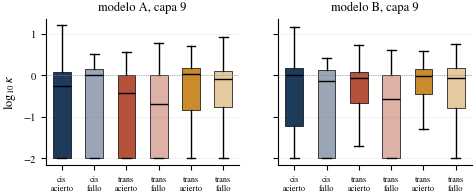

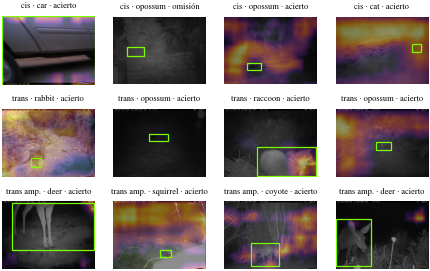

In [25]:
l0, l1 = CFG['cam_capas']; NOMCAPA = {l0: 'Prof', l1: 'Inter'}
def mwu(a, b):
    a, b = np.asarray(a, float)[np.isfinite(np.asarray(a, float))], np.asarray(b, float)[np.isfinite(np.asarray(b, float))]
    return stats.mannwhitneyu(a, b).pvalue if len(a) > 2 and len(b) > 2 else np.nan
for m in MODS:
    kc = CAMDF[(CAMDF.modelo == m) & (CAMDF.split == 'cis_test')]
    for sp in DOMS:
        k = CAMDF[(CAMDF.modelo == m) & (CAMDF.split == sp)]
        for l in (l0, l1):
            macro(f'k{SUF[sp]}{NOMCAPA[l]}{m}', f'{k[f"k_{l}"].astype(float).median():.2f}'); macro(f'e{SUF[sp]}{NOMCAPA[l]}{m}', pct(k[f'E_{l}'].astype(float).median()))
            if sp != 'cis_test': macro(f'pK{SUF[sp]}{NOMCAPA[l]}{m}', f'{mwu(kc[f"k_{l}"], k[f"k_{l}"]):.3f}')
        ok, om = k[k.estado_det == 'correcta'][f'k_{l0}'], k[k.estado_det == 'omitida'][f'k_{l0}']
        macro(f'k{SUF[sp]}Ok{m}', f'{ok.astype(float).median():.2f}'); macro(f'k{SUF[sp]}Omit{m}', f'{om.astype(float).median():.2f}')
        macro(f'pKOmit{SUF[sp]}{m}', f'{mwu(ok, om):.3f}')

fig, ax = plt.subplots(1, len(MODS), figsize=(ANCHO, 1.9), sharey=True, squeeze=False); ax = ax[0]
for j, m in enumerate(MODS):
    datos, etq, cols = [], [], []
    for sp in DOMS:
        k = CAMDF[(CAMDF.modelo == m) & (CAMDF.split == sp)]
        for ok_, nom, a in [(True, 'acierto', 1.), (False, 'fallo', .45)]:
            v = k[(k.estado_det == 'correcta') == ok_][f'k_{l0}'].astype(float).dropna().values
            datos.append(np.log10(np.clip(v, 1e-2, None)) if len(v) else np.array([np.nan])); etq.append(f'{NOMDOM[sp].split()[0]}\n{nom}')
            cols.append(matplotlib.colors.to_rgba(DOMCOL[sp], a))
    bp = ax[j].boxplot(datos, widths=.55, showfliers=False, patch_artist=True)
    for p, c in zip(bp['boxes'], cols): p.set_facecolor(c); p.set_edgecolor('k'); p.set_linewidth(.5)
    for m_ in bp['medians']: m_.set_color('k')
    ax[j].axhline(0, color=COL['gris'], lw=.6, ls=':'); ax[j].set_xticks(range(1, len(etq) + 1)); ax[j].set_xticklabels(etq, fontsize=6)
    ax[j].set_title(f'modelo {m}, capa {l0}'); ax[j].grid(axis='x', alpha=0)
ax[0].set_ylabel(r'$\log_{10}\kappa$'); guardar_fig(fig, 'fig_kappa_gradcam')

mE = MODS[-1]; fig, ax = plt.subplots(3, 4, figsize=(ANCHO, 3.4))
for i, sp in enumerate(DOMS):
    for j in range(4):
        a = ax[i, j]; a.axis('off')
        if j >= len(ejemplos.get((mE, sp), [])): continue
        img, caja, cam, cat, est = ejemplos[(mE, sp)][j]; h, w = img.shape[:2]; cam = cv2.resize(cam, (w, h)); cam = cam / (cam.max() + 1e-9)
        a.imshow(img); a.imshow(cam, cmap='inferno', alpha=.45)
        a.add_patch(plt.Rectangle((caja[0] * w, caja[1] * h), (caja[2] - caja[0]) * w, (caja[3] - caja[1]) * h, fill=False, ec='#7CFC00', lw=.9))
        a.set_title(f'{ {"cis_test": "cis", "trans_test": "trans", "trans_ext": "trans amp."}[sp]} · {cat} · {"acierto" if est == "correcta" else "omisión"}', fontsize=6)
guardar_fig(fig, 'fig_gradcam_ejemplos')

In [26]:
# ---------- contrafactual de fondo (mismas instancias para A y B) ----------
def enmascarar(img, caja, loc):
    h, w = img.shape[:2]; bg, mismo = fondo(loc, modo(img), img.shape[:2])
    x1, y1, x2, y2 = caja; dx, dy = .05 * (x2 - x1), .05 * (y2 - y1)
    X1, Y1, X2, Y2 = int(max(0, x1 - dx) * w), int(max(0, y1 - dy) * h), int(np.ceil(min(1, x2 + dx) * w)), int(np.ceil(min(1, y2 + dy) * h))
    out = img.copy(); mk = np.zeros((h, w), bool); mk[Y1:Y2, X1:X2] = True
    if bg is None: return cv2.inpaint(img, mk.astype(np.uint8) * 255, 5, cv2.INPAINT_TELEA), 'inpaint'
    gan = np.median(img[~mk], 0) / np.maximum(np.median(bg[~mk], 0), 1)
    out[mk] = np.clip(bg[mk].astype(np.float32) * gan, 0, 255).astype(np.uint8); return out, 'fondo' if mismo else 'fondo_otro_modo'

def score_region(xy, sc, cl, caja, c):
    if len(xy) == 0: return 0., 0.
    iou = iou_mat(xy, np.array([caja]))[:, 0]; k = (cl == c) & (iou >= .3)
    return (sc[k].max() if k.any() else 0.), (sc[iou >= .3].max() if (iou >= .3).any() else 0.)

f_cf = f'{CACHE}/contrafactual.csv'
if os.path.exists(f_cf): CF = pd.read_csv(f_cf, dtype={'image_id': str})
else:
    filas = []
    for sp in DOMS:
        g = gt_de(CONJ[sp]); una = g.groupby('image_id').cls.transform('size') == 1
        mu = g[una & (g.cls >= 0)].sample(min(CFG['n_contrafactual'], int((una & (g.cls >= 0)).sum())), random_state=2)
        rutas = CONJ[sp].set_index('image_id').ruta; lote, meta = [], []
        for r in mu.itertuples():
            img = leer_rgb(rutas[r.image_id]); im2, via = enmascarar(img, (r.x1, r.y1, r.x2, r.y2), r.location)
            lote.append(im2[:, :, ::-1].copy()); meta.append((r, via))
        for m in MODS:
            y = YOLO(BEST[m]); Dm = DET[m][sp].groupby('image_id')
            for b in range(0, len(lote), CFG['batch_inf']):
                res = y.predict(lote[b:b + CFG['batch_inf']], imgsz=S, conf=CFG['conf_eval'], iou=CFG['iou_nms'], verbose=False, device=DEV)
                for (r, via), rr in zip(meta[b:b + CFG['batch_inf']], res):
                    bx = rr.boxes; caja = [r.x1, r.y1, r.x2, r.y2]
                    s_c, s_any = score_region(bx.xyxyn.cpu().numpy(), bx.conf.cpu().numpy(), bx.cls.cpu().numpy().astype(int), caja, r.cls)
                    o = Dm.get_group(r.image_id) if r.image_id in Dm.groups else DET[m][sp].iloc[:0]
                    s0, _ = score_region(o[['x1', 'y1', 'x2', 'y2']].values, o.score.values, o.cls.values, caja, r.cls)
                    filas.append(dict(modelo=m, split=sp, image_id=r.image_id, cls=r.cls, via=via, s_orig=s0, s_masc=s_c, s_masc_cualquiera=s_any))
    CF = pd.DataFrame(filas); CF.to_csv(f_cf, index=False)

def persist(d, tau):
    d = d[d.s_orig >= tau]; return ((d.s_masc >= tau).mean() if len(d) else np.nan), len(d)
filas = []
for m in MODS:
    for sp in DOMS:
        d = CF[(CF.modelo == m) & (CF.split == sp)]; p, n = persist(d, TAU[m]); k = CAMDF[(CAMDF.modelo == m) & (CAMDF.split == sp)]
        macro(f'persist{SUF[sp]}{m}', pct(p)); macro(f'nCf{SUF[sp]}{m}', n)
        macro(f'fprVacias{SUF[sp]}{m}', pct(NIV[m][sp]['fpr_vacias'])); macro(f'auc{SUF[sp]}{m}', f'{NIV[m][sp]["auc"]:.3f}')
        filas.append([m, NOMDOM[sp], f'{k[f"k_{l0}"].astype(float).median():.2f}', f'{k[f"k_{l1}"].astype(float).median():.2f}',
                      pct(k[f'E_{l0}'].astype(float).median()), pct(p), pct(NIV[m][sp]['fpr_vacias']), f'{NIV[m][sp]["auc"]:.3f}'])
    filas.append('MIDRULE')
tabla_tex(filas[:-1], ['Modelo', 'Dominio', fr'$\tilde\kappa_{{{l0}}}$', fr'$\tilde\kappa_{{{l1}}}$', fr'$\tilde E_{{\mathrm{{in}}}}$ (\%)',
                       r'Persistencia (\%)', r'FPR$_\varnothing$ (\%)', 'AUROC'], 'tab_fondo')
macro('viaFondo', pct((CF.via != 'inpaint').mean()))

/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/tmp/ipykernel_8616/672838575.py:9: RuntimeWarning: invalid value encountered in cast
  out[mk] = np.clip(bg[mk].astype(np.float32) * gan, 0, 255).astype(np.uint8); return out, 'fondo' if mismo else 'fondo_otro_modo'
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:139: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
/tmp/ipykernel_8616/672838575.py:9: RuntimeWarning: invalid value encountered in cast
  out[mk] = np.clip(bg[mk].astype(np.float32) * gan, 0, 255).astype(np.uint8); return out, 'fondo' if mismo else 'fondo_otro_modo'


\begin{tabular}{lrrrrrrr}
\toprule
Modelo & Dominio & $\tilde\kappa_{9}$ & $\tilde\kappa_{6}$ & $\tilde E_{\mathrm{in}}$ (\%) & Persistencia (\%) & FPR$_\varnothing$ (\%) & AUROC \\
\midrule
A & cis & 0.60 & 0.94 & 1.3 & 8.4 & 14.0 & 0.963 \\
A & trans & 0.34 & 0.90 & 0.7 & 9.7 & 36.7 & 0.865 \\
A & trans ampliado & 0.86 & 1.06 & 5.9 & 4.4 & 34.9 & 0.712 \\
\midrule
B & cis & 0.98 & 0.86 & 2.3 & 0.0 & 30.5 & 0.917 \\
B & trans & 0.82 & 0.94 & 1.6 & 0.0 & 30.8 & 0.922 \\
B & trans ampliado & 0.93 & 1.05 & 5.5 & 35.0 & 21.8 & 0.879 \\
\bottomrule
\end{tabular}


**Lectura de las pruebas de fondo.**

* **Grad-CAM.** La concentración mediana en la capa 9 es menor que 1 en todos los casos, y los mapas resaltan con frecuencia vegetación, bordes y zonas iluminadas antes que al animal.
  * En A, $\tilde\kappa$ baja de 0.60 en cis a 0.34 en trans ($p = 0.072$).
  * B concentra más la evidencia (0.98 y 0.82).
  * El trans ampliado no se compara por $\kappa$, porque sus cajas grandes lo acercan a 1 por construcción.
* **Contrafactual.** Al retirar al animal, la detección desaparece en más del 90 % de los casos de cis y trans. El detector usa al animal cuando lo detecta, y la dependencia del contexto se manifiesta sobre todo como falsos positivos en escenas vacías desconocidas.
  * La persistencia de B en el trans ampliado (35.0 %) no se interpreta: allí predominan cajas que ocupan casi todo el encuadre.
  * Las advertencias numéricas de la celda corresponden a esas cajas, en las que no queda contexto para calcular la ganancia.

## 13. Robustez ante oclusión y tamaño (entregable 4)

CCT no anota oclusión, así que se estima con tres señales observables: $o = \max(o_{\mathrm{vis}}, o_{\mathrm{tr}}, o_{\mathrm{sol}})$.

* **Déficit de visibilidad:** $o_{\mathrm{vis}} = \mathrm{clip}(1 - v/v_{75}(c), 0, 1)$, donde $v$ es la fracción de píxeles de la caja que difieren del fondo de la cámara.
* **Truncamiento por el borde del encuadre:** $o_{\mathrm{tr}}$ vale 0.5 si la caja toca un borde y 0.8 si toca dos o más.
* **Solapamiento con otra caja:** $o_{\mathrm{sol}}$, la fracción de la caja cubierta por otra caja verdadera.

Los niveles son bajo $[0, 1/3)$, medio $[1/3, 2/3)$ y alto $[2/3, 1]$. El tamaño sigue los umbrales de COCO a la resolución de entrada.
El indicador principal es el recall a $\tau^\ast$, que no depende de cómo se atribuyan los falsos positivos a cada grupo.

tamano                     grande  mediano  pequeño
split      nivel_oclusion                          
cis_test   alto              3031     3891      123
           bajo              1715     2049       19
           medio             1211     1197       28
trans_ext  alto              1348      369       63
           bajo              1743      763       88
           medio             1257      374       50
trans_test alto              4480     5745       99
           bajo              1384     2693       17
           medio             2072     2285       11
\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{3}{c}{cis} & \multicolumn{3}{c}{trans} & \multicolumn{3}{c}{trans ampliado} \\ \cmidrule(lr){2-4}\cmidrule(lr){5-7}\cmidrule(lr){8-10}
Subgrupo & $n$ & R@$\tau^\ast$ A & R@$\tau^\ast$ B & $n$ & R@$\tau^\ast$ A & R@$\tau^\ast$ B & $n$ & R@$\tau^\ast$ A & R@$\tau^\ast$ B \\
\midrule
Oclusión bajo & 3\,783 & 90.9 & 92.3 & 4\,094 & 77.2 & 82.9 & 2\,479 & 17.4 & 65.2 \\
Oclusió

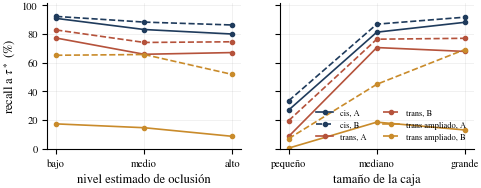

In [27]:
f_oc = f'{CACHE}/oclusion.parquet'
if os.path.exists(f_oc): OC = pd.read_parquet(f_oc)
else:
    partes = []
    for sp in DOMS:
        g = R[MODS[0]][sp]['gt'].copy(); g['split'] = sp; g['gidx'] = np.arange(len(g))
        dims_ = CONJ[sp].set_index('image_id')[['w', 'h', 'ruta', 'location']]
        vis = np.full(len(g), np.nan)
        for iid, gg in g.groupby('image_id'):
            img = leer_rgb(dims_.ruta[iid]); H, W = img.shape[:2]; bg, _ = fondo(dims_.location[iid], modo(img), (H, W))
            if bg is None: continue
            gi = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32); gb = cv2.cvtColor(bg, cv2.COLOR_RGB2GRAY).astype(np.float32)
            dentro = np.zeros((H, W), bool)
            for r in gg.itertuples(): dentro[int(r.y1 * H):int(np.ceil(r.y2 * H)), int(r.x1 * W):int(np.ceil(r.x2 * W))] = True
            fuera = ~dentro if (~dentro).mean() > .05 else np.ones_like(dentro)
            D = cv2.GaussianBlur(np.abs(gi - gb * np.median(gi[fuera]) / max(np.median(gb[fuera]), 1)), (5, 5), 0)
            md_ = np.median(D[fuera]); thr = max(12., md_ + 3 * 1.4826 * np.median(np.abs(D[fuera] - md_)))
            for r in gg.itertuples():
                cj = D[int(r.y1 * H):int(np.ceil(r.y2 * H)), int(r.x1 * W):int(np.ceil(r.x2 * W))]
                if cj.size: vis[r.gidx] = (cj > thr).mean()
        g['vis'] = vis; e = .005
        g['bordes'] = (g.x1 <= e).astype(int) + (g.y1 <= e) + (g.x2 >= 1 - e) + (g.y2 >= 1 - e); sol = np.zeros(len(g))
        for iid, gg in g.groupby('image_id'):
            if len(gg) < 2: continue
            B = gg[['x1', 'y1', 'x2', 'y2']].values
            ix = np.clip(np.minimum(B[:, None, 2], B[None, :, 2]) - np.maximum(B[:, None, 0], B[None, :, 0]), 0, None)
            iy = np.clip(np.minimum(B[:, None, 3], B[None, :, 3]) - np.maximum(B[:, None, 1], B[None, :, 1]), 0, None)
            ioa = ix * iy / ((B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1]))[:, None]; np.fill_diagonal(ioa, 0); sol[gg.gidx.values] = ioa.max(1)
        g['solape'] = sol; g = g.join(dims_[['w', 'h']], on='image_id'); g['area_px'] = (g.x2 - g.x1) * g.w * (g.y2 - g.y1) * g.h
        partes.append(g.drop(columns=['gidx']))
    OC = pd.concat(partes, ignore_index=True)
    v75 = OC[OC.cls >= 0].groupby('cls').vis.quantile(.75)
    OC['o_vis'] = (1 - OC.vis / OC.cls.map(v75).clip(lower=1e-3)).clip(0, 1)
    OC['o_tr'] = np.select([OC.bordes >= 2, OC.bordes == 1], [.8, .5], 0.)
    OC['o'] = OC[['o_vis', 'o_tr', 'solape']].max(axis=1, skipna=True)
    OC['nivel_oclusion'] = pd.cut(OC.o, [-.01, 1 / 3, 2 / 3, 1.01], labels=['bajo', 'medio', 'alto']).astype(str)
    OC['tamano'] = pd.cut(OC.area_px, [0, 32 ** 2, 96 ** 2, 1e12], labels=['pequeño', 'mediano', 'grande'], right=False).astype(str)
    OC.to_parquet(f_oc)
print(pd.crosstab([OC.split, OC.nivel_oclusion], OC.tamano)); macro('pctSinFondo', pct(OC.vis.isna().mean()))

NIVELES = {'oclusion': ('nivel_oclusion', ['bajo', 'medio', 'alto']), 'tamano': ('tamano', ['pequeño', 'mediano', 'grande'])}
RANGO = {'pequeño': (0, 32 ** 2), 'mediano': (32 ** 2, 96 ** 2), 'grande': (96 ** 2, 1e12)}
f_sg = f'{CACHE}/subgrupos.json'
SG = json.load(open(f_sg)) if os.path.exists(f_sg) else []
hechos_sg = {(s['modelo'], s['split'], s['eje'], s['nivel']) for s in SG}
for m in MODS:
    for sp in DOMS:
        o = OC[OC.split == sp].reset_index(drop=True); ids = CONJ[sp].image_id.tolist(); wh = CONJ[sp].set_index('image_id')[['w', 'h']]
        for eje, (col, nivs) in NIVELES.items():
            for nv in nivs:
                if (m, sp, eje, nv) in hechos_sg: continue
                dentro = (o[col] == nv).values
                fuera = None
                if eje == 'tamano':
                    lo, hi = RANGO[nv]
                    def fuera(d, lo=lo, hi=hi):
                        a = (d.x2 - d.x1).values * d.image_id.map(wh.w).values * (d.y2 - d.y1).values * d.image_id.map(wh.h).values
                        return (a < lo) | (a >= hi)
                Rg = emparejar(o, DET[m][sp], ids, gt_ign=lambda g, mk=dentro: ~mk, dt_fuera=fuera); s = resumen(acumular(Rg, W0[sp])[0])
                gm = R[m][sp]['g_ms'][0][dentro & (o.cls.values >= 0)]
                SG.append(dict(modelo=m, split=sp, eje=eje, nivel=nv, n=int((dentro & (o.cls.values >= 0)).sum()),
                               ap50=float(s['map50']), rec_tau=float((gm >= TAU[m]).mean()) if len(gm) else float('nan')))
                json.dump(SG, open(f_sg, 'w'))
SG = pd.DataFrame(SG)
def sg(m, sp, eje, nv, col='rec_tau'):
    q = SG[(SG.modelo == m) & (SG.split == sp) & (SG.eje == eje) & (SG.nivel == nv)]; return q[col].iloc[0] if len(q) else np.nan
filas = []
for eje, (col, nivs) in NIVELES.items():
    for nv in nivs:
        f = [('Oclusión ' if eje == 'oclusion' else 'Tamaño ') + nv]
        for sp in DOMS: f += [num(sg(MODS[0], sp, eje, nv, 'n'))] + [pct(sg(m, sp, eje, nv)) for m in MODS]
        filas.append(f)
    if eje == 'oclusion': filas.append('MIDRULE')
grp = ' & ' + ' & '.join(fr'\multicolumn{{{1 + len(MODS)}}}{{c}}{{{NOMDOM[sp]}}}' for sp in DOMS) + r' \\ ' + ''.join(
    fr'\cmidrule(lr){{{2 + i * (1 + len(MODS))}-{1 + (i + 1) * (1 + len(MODS))}}}' for i in range(len(DOMS)))
tabla_tex(filas, ['Subgrupo'] + (['$n$'] + [f'R@$\\tau^\\ast$ {m}' for m in MODS]) * len(DOMS), 'tab_oclusion_tamano', grupos=grp)
for m in MODS:
    for sp in DOMS:
        macro(f'caidaOcl{SUF[sp]}{m}', pct(sg(m, sp, 'oclusion', 'bajo') - sg(m, sp, 'oclusion', 'alto')))
        macro(f'caidaTam{SUF[sp]}{m}', pct(sg(m, sp, 'tamano', 'grande') - sg(m, sp, 'tamano', 'pequeño')))
        macro(f'recPeq{SUF[sp]}{m}', pct(sg(m, sp, 'tamano', 'pequeño'))); macro(f'recOclAlto{SUF[sp]}{m}', pct(sg(m, sp, 'oclusion', 'alto')))

fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 1.9), sharey=True)
for j, (eje, (col, nivs)) in enumerate(NIVELES.items()):
    for sp in DOMS:
        for m in MODS:
            ax[j].plot(nivs, [100 * sg(m, sp, eje, nv) for nv in nivs], marker='o', ms=3, color=DOMCOL[sp],
                       ls='-' if m == MODS[0] else '--', label=f'{NOMDOM[sp]}, {m}')
    ax[j].set_xlabel('nivel estimado de oclusión' if eje == 'oclusion' else 'tamaño de la caja'); ax[j].set_ylim(0, 102)
ax[0].set_ylabel(r'recall a $\tau^\ast$ (%)'); ax[1].legend(frameon=False, fontsize=6, loc='lower right', ncol=2)
guardar_fig(fig, 'fig_oclusion_tamano')

**Tamaño frente a oclusión.**

* **Tamaño.** Es el factor dominante. Las cajas pequeñas son entre el 1 % y el 3 % del total, pero su recall a $\tau^\ast$ es de 27.1 % en cis y 8.7 % en trans con A, frente a más del 80 % en las grandes de cis. B solo sube el recall de las pequeñas en trans a 19.7 %. Es una consecuencia esperable de trabajar a 640 px.
* **Oclusión estimada.** Tiene un efecto monótono pero moderado: el recall cae unos 10 puntos entre los niveles bajo y alto en cis y trans. El estimador asigna el nivel alto a más de la mitad de las cajas, lo que indica umbrales conservadores. Hasta completar la validación manual, sus niveles se interpretan como un orden relativo.

In [28]:
# ---------- validación manual del estimador de oclusión ----------
# Completa 'nivel_manual' (bajo/medio/alto) en resultados/oclusion_validacion.csv y guárdalo como P3_CCT20/oclusion_validacion_lleno.csv.
f_val = f'{RES}/oclusion_validacion.csv'
if not os.path.exists(f_val):
    mu = pd.concat([g.sample(min(40, len(g)), random_state=3) for _, g in OC[OC.cls >= 0].groupby('nivel_oclusion')])
    mu = mu.sample(frac=1, random_state=4).reset_index(drop=True); mu['id_val'] = np.arange(len(mu))
    mu[['id_val', 'split', 'image_id', 'cat', 'x1', 'y1', 'x2', 'y2', 'nivel_oclusion']].assign(nivel_manual='').to_csv(f_val, index=False)
    rutas = pd.concat([CONJ[sp] for sp in DOMS]).drop_duplicates('image_id').set_index('image_id').ruta
    n = len(mu); cols = 10; fil = int(np.ceil(n / cols)); fig, ax = plt.subplots(fil, cols, figsize=(8.5, .95 * fil))
    for a in ax.ravel(): a.axis('off')
    for r in mu.itertuples():
        img = leer_rgb(rutas[r.image_id]); h, w = img.shape[:2]
        x1, y1, x2, y2 = int(max(0, r.x1 - .03) * w), int(max(0, r.y1 - .03) * h), int(min(1, r.x2 + .03) * w), int(min(1, r.y2 + .03) * h)
        a = ax.ravel()[r.id_val]; a.imshow(img[y1:y2, x1:x2]); a.set_title(str(r.id_val), fontsize=6)
    fig.savefig(f'{RES}/oclusion_validacion_hoja.pdf'); plt.close(fig)
f_lleno = f'{WORK}/oclusion_validacion_lleno.csv'
if os.path.exists(f_lleno):
    from sklearn.metrics import cohen_kappa_score
    v = pd.read_csv(f_lleno).dropna(subset=['nivel_manual']); v = v[v.nivel_manual.isin(['bajo', 'medio', 'alto'])]; o_ = {'bajo': 0, 'medio': 1, 'alto': 2}
    macro('kappaOcl', f'{cohen_kappa_score(v.nivel_oclusion.map(o_), v.nivel_manual.map(o_), weights="quadratic"):.2f}')
    macro('accOcl', pct((v.nivel_oclusion == v.nivel_manual).mean())); macro('nValOcl', len(v))
else: print('Validación manual pendiente:', f_val)

Validación manual pendiente: /content/drive/MyDrive/P3_CCT20/resultados/oclusion_validacion.csv


La validación manual sigue pendiente. Para completarla:

1. Revisa la hoja de 120 recortes exportada.
2. Completa la columna `nivel_manual` del CSV.
3. Guárdalo como `oclusion_validacion_lleno.csv` en `MyDrive/P3_CCT20/`.
4. Vuelve a ejecutar esta celda: calcula el κ ponderado y lo agrega a `metricas.tex`.

## 14. Módulo de monitoreo ecológico (entregable 5)

El módulo se aplica al flujo completo de una cámara del trans ampliado que ningún modelo vio, con sus vacías e imágenes sin caja. Sus
cinco reglas son:

* **R1. Filtrado:** se conservan las detecciones con puntuación $\ge \tau^\ast$.
* **R2. Supresión entre especies:** NMS agnóstico con IoU 0.6, para que un individuo no cuente como dos especies.
* **R3. Fotograma:** cada fotograma queda vacío o con su lista de individuos por especie.
* **R4. Evento independiente:** dos registros de una especie son eventos distintos si los separan más de 30 min (O'Brien et al., 2003).
* **R5. Abundancia:** MaxN por evento e índice de abundancia relativa, IAR = eventos / días × 100.

El reporte de referencia se obtiene aplicando el mismo módulo a las etiquetas verdaderas.

Cámara de demostración 60 | fotogramas 405 | vacías 10.9%
ref {'fotogramas': 405, 'pct_vacios': 0.10864197530864195, 'especies': 8, 'eventos': 49, 'dias': 177}
A {'fotogramas': 405, 'pct_vacios': 0.5851851851851853, 'especies': 9, 'eventos': 48, 'dias': 177}
B {'fotogramas': 405, 'pct_vacios': 0.5382716049382716, 'especies': 12, 'eventos': 62, 'dias': 177}
\begin{tabular}{lrrr}
\toprule
Indicador & Referencia & Módulo A & Módulo B \\
\midrule
Fotogramas analizados & 405 & 405 & 405 \\
Fotogramas sin fauna (\%) & 10.9 & 58.5 & 53.8 \\
Especies distintas & 8 & 9 & 12 \\
Eventos independientes & 49 & 48 & 62 \\
Días de operación & 177 & 177 & 177 \\
\bottomrule
\end{tabular}
\begin{tabular}{lrrrrrrrr}
\toprule
Especie & Madrug. & Mañana & Tarde & Noche & Eventos & MaxN & IAR & Eventos A \\
\midrule
bird & 0 (0) & 3 (0) & 0 (1) & 0 (0) & 3 (1) & 1 (1) & 1.7 (0.6) & 2 \\
bobcat & 4 (3) & 0 (0) & 4 (2) & 6 (4) & 14 (9) & 1 (1) & 7.9 (5.1) & 9 \\
cat & 0 (0) & 0 (0) & 0 (0) & 1 (1) & 1 (1) & 

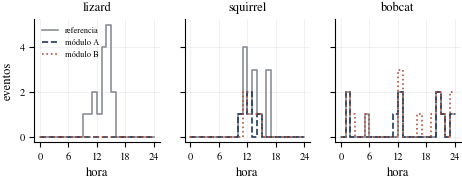

In [29]:
NO_FAUNA = {'car'}
class MonitorEcologico:
    PERIODOS = [(0, 6, 'madrugada'), (6, 12, 'mañana'), (12, 18, 'tarde'), (18, 24, 'noche')]
    def __init__(self, tau, iou_agn=0.6, minutos_indep=30):
        self.tau, self.iou_agn, self.dt_indep = tau, iou_agn, pd.Timedelta(minutes=minutos_indep)
    def filtrar(self, det):
        d = det[det.score >= self.tau]; out = []
        for iid, g in d.groupby('image_id'):
            k = nms(torch.tensor(g[['x1', 'y1', 'x2', 'y2']].values, dtype=torch.float32), torch.tensor(g.score.values, dtype=torch.float32), self.iou_agn).numpy()
            out.append(g.iloc[k])
        return pd.concat(out) if out else d.iloc[:0]
    def obs_pred(self, imgs, det):
        d = self.filtrar(det); d = d.assign(especie=d.cls.map(dict(enumerate(CLASES))))
        return d.groupby(['image_id', 'especie']).size().rename('n').reset_index().merge(imgs[['image_id', 'fecha']], on='image_id')
    @staticmethod
    def obs_real(imgs, cajas):
        c = cajas[cajas.image_id.isin(set(imgs.image_id))].groupby(['image_id', 'cat']).size().rename('n').reset_index().rename(columns={'cat': 'especie'})
        sin = imgs[imgs.estado == 'animal_sin_caja'].explode('etiquetas'); sin = sin[sin.etiquetas != 'empty']
        o = pd.concat([c, sin[['image_id', 'etiquetas']].rename(columns={'etiquetas': 'especie'}).assign(n=1)], ignore_index=True)
        return o.merge(imgs[['image_id', 'fecha']], on='image_id')
    def eventos(self, obs):
        obs = obs[~obs.especie.isin(NO_FAUNA)].dropna(subset=['fecha']).sort_values('fecha'); ev = []
        for esp, g in obs.groupby('especie'):
            g = g.assign(evento=(g.fecha.diff().gt(self.dt_indep) | g.fecha.diff().isna()).cumsum())
            for _, ge in g.groupby('evento'): ev.append(dict(especie=esp, inicio=ge.fecha.min(), maxn=int(ge.n.max()), fotogramas=len(ge)))
        ev = pd.DataFrame(ev, columns=['especie', 'inicio', 'maxn', 'fotogramas'])
        if len(ev): ev['periodo'] = pd.cut(ev.inicio.dt.hour, [p[0] for p in self.PERIODOS] + [24], right=False, labels=[p[2] for p in self.PERIODOS])
        return ev
    def reporte(self, imgs, obs):
        ev = self.eventos(obs); dias = max((imgs.fecha.max() - imgs.fecha.min()).days + 1, 1) if imgs.fecha.notna().any() else np.nan
        con = set(obs[~obs.especie.isin(NO_FAUNA)].image_id)
        res = dict(fotogramas=len(imgs), pct_vacios=1 - len(con) / len(imgs), especies=ev.especie.nunique(), eventos=len(ev), dias=dias)
        if len(ev) == 0: return res, pd.DataFrame(columns=[p[2] for p in self.PERIODOS] + ['total', 'maxn', 'iar']), ev
        tab = ev.pivot_table(index='especie', columns='periodo', values='maxn', aggfunc='size', fill_value=0, observed=False)
        tab['total'] = tab.sum(1); tab['maxn'] = ev.groupby('especie').maxn.max(); tab['iar'] = 100 * tab.total / dias
        return res, tab, ev

I_demo = IMGS[IMGS.location == LOC_DEMO].sort_values('fecha').reset_index(drop=True)
print('Cámara de demostración', LOC_DEMO, '| fotogramas', len(I_demo), '| vacías', f'{(I_demo.estado == "vacia").mean():.1%}')
REP = {'ref': MonitorEcologico(0).reporte(I_demo, MonitorEcologico.obs_real(I_demo, CAJAS))}
for m in MODS:
    D = inferir(m, f'demo_{LOC_DEMO}', I_demo.ruta.tolist(), I_demo.image_id.tolist()); mon = MonitorEcologico(TAU[m])
    REP[m] = mon.reporte(I_demo, mon.obs_pred(I_demo, D))
for k, (res, tab, ev) in REP.items():
    tab.to_csv(f'{RES}/monitoreo_{k}.csv'); ev.to_csv(f'{RES}/monitoreo_eventos_{k}.csv', index=False); print(k, res)

claves = ['ref'] + MODS
filas = [['Fotogramas analizados'] + [num(REP[k][0]['fotogramas']) for k in claves],
         [r'Fotogramas sin fauna (\%)'] + [pct(REP[k][0]['pct_vacios']) for k in claves],
         ['Especies distintas'] + [str(REP[k][0]['especies']) for k in claves],
         ['Eventos independientes'] + [str(REP[k][0]['eventos']) for k in claves],
         ['Días de operación'] + [str(REP[k][0]['dias']) for k in claves]]
tabla_tex(filas, ['Indicador', 'Referencia'] + [f'Módulo {m}' for m in MODS], 'tab_monitoreo_resumen', alin='l' + 'r' * len(claves))
tr = REP['ref'][1]; tb = REP[MODS[-1]][1]; ta = REP[MODS[0]][1]
per = [p[2] for p in MonitorEcologico.PERIODOS]
def cel(t, e, c, f=lambda x: str(int(x))): return f(t.loc[e, c]) if e in t.index and c in t.columns else '0'
filas = []
for e in list(dict.fromkeys(list(tr.index) + list(tb.index))):
    filas.append([tex_esc(e)] + [f'{cel(tb, e, c)} ({cel(tr, e, c)})' for c in per + ['total', 'maxn']] +
                 [f'{cel(tb, e, "iar", lambda x: f"{x:.1f}")} ({cel(tr, e, "iar", lambda x: f"{x:.1f}")})', cel(ta, e, 'total')])
tabla_tex(filas, ['Especie', 'Madrug.', 'Mañana', 'Tarde', 'Noche', 'Eventos', 'MaxN', 'IAR', f'Eventos {MODS[0]}'], 'tab_monitoreo_especies')
macro('fotogramasDemo', num(len(I_demo))); macro('diasDemo', REP['ref'][0]['dias'])
for k, nom in [('ref', 'Real')] + [(m, m) for m in MODS]:
    macro(f'eventos{nom}', REP[k][0]['eventos']); macro(f'especies{nom}', REP[k][0]['especies']); macro(f'vacios{nom}', pct(REP[k][0]['pct_vacios']))
for m in MODS:
    t = REP[m][1]; err = (t.reindex(tr.index)['total'].fillna(0) - tr.total).abs().sum() / max(tr.total.sum(), 1) if len(tr) else np.nan
    macro(f'errEventos{m}', pct(err))

top = REP['ref'][2].especie.value_counts().index[:3]
fig, ax = plt.subplots(1, max(len(top), 1), figsize=(ANCHO, 1.6), sharey=True, squeeze=False); ax = ax[0]
for j, e in enumerate(top):
    for k, c, ls, lab in [('ref', COL['gris'], '-', 'referencia')] + [(m, COL[m], '--' if m == MODS[0] else ':', f'módulo {m}') for m in MODS]:
        ev = REP[k][2]; h = np.bincount(ev[ev.especie == e].inicio.dt.hour, minlength=24)
        ax[j].step(np.arange(25), np.r_[h, h[-1]], where='post', color=c, ls=ls, label=lab)
    ax[j].set_title(e); ax[j].set_xlabel('hora'); ax[j].set_xticks([0, 6, 12, 18, 24])
ax[0].set_ylabel('eventos'); ax[0].legend(frameon=False, fontsize=6); guardar_fig(fig, 'fig_actividad_monitoreo')

**Lectura del reporte de monitoreo.** En la cámara 60, la referencia registra 49 eventos de 8 especies. A obtiene 48 eventos y B 62, pero
la coincidencia del total de A resulta de compensar errores:

* **Lagartija:** ninguno de los dos registra sus 16 eventos, porque no pertenece al espacio de etiquetas.
* **Ardilla:** ambos registran 5 eventos de los 13 de la referencia.
* **Especies inventadas:** A agrega 10 eventos de coyote y B 19 de ciervo.

El error agregado por especie es de 61.2 % y 69.4 %. Zarigüeya y mapache quedan a un evento de la referencia. Un total correcto, por tanto, no
garantiza un inventario correcto, y la especie ajena al espacio de etiquetas desaparece del reporte sin señal de alerta.

## 15. Extensión entre conjuntos de datos: ENA24-detection

ENA24-detection (Yousif et al., 2019) proviene del este de Norteamérica, de un bosque templado caducifolio y con otro hardware de captura.
Se eligió frente a conjuntos neotropicales como Orinoquía por dos razones: anota cajas en todas sus imágenes, lo que permite el mismo mAP
que en los demás dominios, y comparte 13 de las 15 clases de CCT-20.

Cada taxón se asigna a la clase de CCT más específica que lo contiene; por ejemplo, ardillas listadas y marmotas van a `squirrel`. Los
taxones sin clase contenedora, como caballo y oso negro, se conservan en la evaluación agnóstica a la especie.

**Nota sobre la ejecución mostrada.** La salida de esta celda se obtuvo con una versión de `REGLAS` en la que la regla `fox` precedía a
`squirrel`. Por eso *eastern fox squirrel* (*Sciurus niger*) quedó asignada a `fox`, como muestra el mapeo impreso. El código ya tiene
el orden corregido. Volver a ejecutar esta celda y la siguiente actualiza las métricas de ENA24, y el cambio afecta solo a las clases
`fox` y `squirrel`.

Redimensionando 8789 imágenes a 640 px
439 s
mapeo ENA24 -> CCT: {'bird': 'bird', 'eastern gray squirrel': 'squirrel', 'eastern chipmunk': 'squirrel', 'woodchuck': 'squirrel', 'wild turkey': 'bird', 'white tailed deer': 'deer', 'virginia opossum': 'opossum', 'eastern cottontail': 'rabbit', 'human': None, 'vehicle': 'car', 'striped skunk': 'skunk', 'red fox': 'fox', 'eastern fox squirrel': 'fox', 'northern raccoon': 'raccoon', 'grey fox': 'fox', 'horse': None, 'dog': 'dog', 'american crow': 'bird', 'chicken': 'bird', 'domestic cat': 'cat', 'coyote': 'coyote', 'bobcat': 'bobcat', 'american black bear': None}


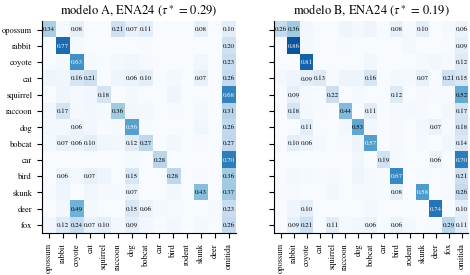

AP agnóstico: {'A': {'cis_test': np.float64(0.9276410863265754), 'trans_test': np.float64(0.8529190831357286), 'trans_ext': np.float64(0.20845132567462318), 'ena24': np.float64(0.692568474641159)}, 'B': {'cis_test': np.float64(0.9368018485157799), 'trans_test': np.float64(0.8908422375023434), 'trans_ext': np.float64(0.5801971781493653), 'ena24': np.float64(0.8299196484912388)}}


In [30]:
REGLAS = [('opossum', 'opossum'), ('raccoon', 'raccoon'), ('coyote', 'coyote'), ('bobcat', 'bobcat'), ('domestic cat', 'cat'), ('dog', 'dog'),
          ('squirrel', 'squirrel'), ('fox', 'fox'), ('skunk', 'skunk'), ('cottontail', 'rabbit'), ('rabbit', 'rabbit'), ('chipmunk', 'squirrel'),
          ('woodchuck', 'squirrel'), ('deer', 'deer'), ('vehicle', 'car'), ('crow', 'bird'), ('turkey', 'bird'), ('chicken', 'bird'),
          ('bird', 'bird'), ('horse', None), ('bear', None), ('human', None), ('cat', 'cat')]
def mapear(n):
    for k, v in REGLAS:
        if k in n: return v if v in CID else None
    return None
def agnostico(det, iou=0.7):
    out = []
    for iid, g in det.groupby('image_id'):
        k = nms(torch.tensor(g[['x1', 'y1', 'x2', 'y2']].values, dtype=torch.float32), torch.tensor(g.score.values, dtype=torch.float32), iou).numpy()
        out.append(g.iloc[k[:CFG['max_det']]])
    return pd.concat(out, ignore_index=True).assign(cls=0) if out else det.assign(cls=0)

if CFG['usar_ena24']:
    DIR_E, DIMS_E = preparar_imagenes('ena24', crudo_ena)
    e = json.load(open(f'{ANOT}/ena24.json')); ecat = {c['id']: norm_nombre(c['name']) for c in e['categories']}
    MAPEO = {n: mapear(n) for n in ecat.values()}; print('mapeo ENA24 -> CCT:', MAPEO)
    dE = DIMS_E.assign(id=DIMS_E.id.astype(str)).set_index('id')
    ei = pd.DataFrame([dict(image_id=str(i['id']), file=os.path.splitext(os.path.basename(i['file_name']))[0], wj=i.get('width'), hj=i.get('height')) for i in e['images']])
    ei = ei[ei.file.isin(dE.index)].reset_index(drop=True)
    ei['w'] = ei.file.map(dE.w); ei['h'] = ei.file.map(dE.h); ei['wj'] = ei.wj.fillna(ei.file.map(dE.ow)); ei['hj'] = ei.hj.fillna(ei.file.map(dE.oh))
    ei['ruta'] = DIR_E + '/' + ei.file + '.jpg'; ei['estado'] = 'animal_con_caja'; ei['location'] = 'ena24'
    wh = ei.set_index('image_id')[['wj', 'hj']]; filas = []
    for a in e['annotations']:
        iid = str(a['image_id']); n = ecat[a['category_id']]
        if iid not in wh.index or a.get('bbox') is None or 'human' in n: continue
        x, y, w, h = a['bbox']; W, H = wh.loc[iid]
        filas.append(dict(image_id=iid, cat=n, cls=CID[MAPEO[n]] if MAPEO[n] else -1, x1=x / W, y1=y / H, x2=(x + w) / W, y2=(y + h) / H))
    GE = pd.DataFrame(filas); GE[['x1', 'y1', 'x2', 'y2']] = GE[['x1', 'y1', 'x2', 'y2']].clip(0, 1)
    ei = ei[ei.image_id.isin(set(GE.image_id))].reset_index(drop=True); CONJ['ena24'] = ei; W0['ena24'] = np.ones(len(ei), int)
    rng_e = np.random.default_rng(0); bidx = [np.bincount(rng_e.integers(0, len(ei), len(ei)), minlength=len(ei)) for _ in range(CFG['n_boot'])]
    for m in MODS:
        DET[m]['ena24'] = inferir(m, 'ena24', ei.ruta.tolist(), ei.image_id.tolist())
        R[m]['ena24'] = emparejar(GE, DET[m]['ena24'], ei.image_id.tolist()); RES_AP[m]['ena24'] = resumen(acumular(R[m]['ena24'])[0])
        DESC[m]['ena24'] = descomponer(GE, DET[m]['ena24'], TAU[m])
        lo, hi = ic(np.array([np.nanmean(acumular(R[m]['ena24'], w)[0][0]) for w in bidx]))
        macro(f'mapEnaCinc{m}', pct(RES_AP[m]['ena24']['map50'])); macro(f'mapEnaCoco{m}', pct(RES_AP[m]['ena24']['map']))
        macro(f'icEna{m}Lo', pct(lo)); macro(f'icEna{m}Hi', pct(hi))
    fig_confusion('ena24', 'fig_confusion_ena24')
    macro('nEna', num(len(ei))); macro('nCajasEna', num(len(GE))); macro('nClasesEna', len({v for v in MAPEO.values() if v}))
    macro('pctNoMapeadas', pct((GE.cls < 0).mean()))

# AP agnóstico a la especie en todos los dominios
AGN = {m: {} for m in MODS}
for m in MODS:
    for sp in DOMS + (['ena24'] if CFG['usar_ena24'] else []):
        g = (GE if sp == 'ena24' else R[m][sp]['gt']).assign(cls=0)
        Ra = emparejar(g, agnostico(DET[m][sp]), CONJ[sp].image_id.tolist()); AP, _ = acumular(Ra, W0[sp], clases=[0])
        AGN[m][sp] = AP[0, 0]; macro(f'agn{SUF[sp]}{m}', pct(AP[0, 0]))
print('AP agnóstico:', AGN)

**Transferencia a otra región.** En ENA24, el mAP@0.5 es de 18.2 % con A y de 33.2 % con B, mientras que el AP agnóstico es de 69.3 % y
83.0 %. Los detectores encuentran a los animales del otro bioma pero fallan al nombrarlos. El ciervo de cola blanca lo ilustra: A, con 44
cajas de entrenamiento, lo clasifica como coyote en el 49 % de los casos, y B alcanza un AP de 52.4 %. Esta diferencia entre localizar y clasificar
respalda un esquema de dos etapas, con un detector agnóstico seguido de un clasificador regional.

## 16. Tablas de síntesis y exportación

La última celda reúne la tabla global por dominio y modelo y la tabla de AP por especie, y empaqueta todas las figuras (PDF) y tablas
(`.tex`) en `resultados_P3.zip`. El informe NeurIPS las lee directamente desde la carpeta `resultados/`.

In [31]:
DOMS_T = DOMS + (['ena24'] if CFG['usar_ena24'] else [])
filas = []
for sp in DOMS_T:
    for m in MODS:
        d = DESC[m][sp]; d = d[d.cls >= 0]; f = d.estado_det.value_counts(normalize=True)
        filas.append([NOMDOM[sp] if m == MODS[0] else '', m, pct(RES_AP[m][sp]['map50']), pct(RES_AP[m][sp]['map']), pct(AGN[m][sp]),
                      pct(f.get('correcta', 0)), pct(f.get('mal_clasificada', 0)), pct(f.get('omitida', 0)),
                      pct(NIV[m].get(sp, {}).get('fpr_vacias', np.nan))])
        macro(f'omit{SUF[sp]}{m}', pct(f.get('omitida', 0))); macro(f'confu{SUF[sp]}{m}', pct(f.get('mal_clasificada', 0)))
    filas.append('MIDRULE')
grp = r' & & \multicolumn{3}{c}{Detección} & \multicolumn{3}{c}{Cajas reales a $\tau^\ast$ (\%)} & \\ \cmidrule(lr){3-5}\cmidrule(lr){6-8}'
tabla_tex(filas[:-1], ['Dominio', 'Mod.', r'mAP$_{50}$', r'mAP$_{50:95}$', r'AP$_{50}^{\mathrm{agn}}$', 'Correcta', 'Confundida', 'Omitida',
                       r'FPR$_{\varnothing}$'], 'tab_global', grupos=grp)

filas = []
for k in np.argsort(-N_TRAIN[MODS[0]]):
    f = [tex_esc(CLASES[k])] + [num(N_TRAIN[m][k]) for m in MODS]
    for sp in DOMS_T: f += [pct(RES_AP[m][sp]['ap50'][k]) for m in MODS]
    filas.append(f)
filas.append('MIDRULE')
filas.append([r'\textbf{mAP}'] + [num(N_TRAIN[m].sum()) for m in MODS] + [pct(RES_AP[m][sp]['map50']) for sp in DOMS_T for m in MODS])
nm = len(MODS)
grp = r' & \multicolumn{%d}{c}{$n_{\mathrm{train}}$}' % nm + ''.join(r' & \multicolumn{%d}{c}{%s}' % (nm, NOMDOM[sp]) for sp in DOMS_T) + r' \\ ' + ''.join(
    r'\cmidrule(lr){%d-%d}' % (2 + i * nm, 1 + (i + 1) * nm) for i in range(len(DOMS_T) + 1))
tabla_tex(filas, ['Especie'] + MODS * (len(DOMS_T) + 1), 'tab_especies', grupos=grp)

pd.DataFrame([dict(modelo=m, dominio=sp, especie=CLASES[k], ap50=RES_AP[m][sp]['ap50'][k], ap=RES_AP[m][sp]['ap'][k])
              for m in MODS for sp in DOMS_T for k in range(NC)]).to_csv(f'{RES}/ap_por_especie.csv', index=False)
json.dump({k: (v if not isinstance(v, np.generic) else v.item()) for k, v in CFG.items()}, open(f'{RES}/config_usada.json', 'w'), indent=1, default=str)
arch = shutil.make_archive(f'{WORK}/resultados_P3', 'zip', RES); print('Resultados empaquetados en', arch); print(sorted(os.listdir(RES)))
if EN_COLAB and not MODO_PRUEBA:
    from google.colab import files
    try: files.download(arch)
    except Exception: print('Descarga manual desde Drive:', arch)

\begin{tabular}{lrrrrrrrr}
\toprule
 & & \multicolumn{3}{c}{Detección} & \multicolumn{3}{c}{Cajas reales a $\tau^\ast$ (\%)} & \\ \cmidrule(lr){3-5}\cmidrule(lr){6-8}
Dominio & Mod. & mAP$_{50}$ & mAP$_{50:95}$ & AP$_{50}^{\mathrm{agn}}$ & Correcta & Confundida & Omitida & FPR$_{\varnothing}$ \\
\midrule
cis & A & 66.6 & 44.0 & 92.8 & 83.8 & 7.0 & 9.3 & 14.0 \\
 & B & 73.5 & 50.8 & 93.7 & 88.4 & 5.5 & 6.1 & 30.5 \\
\midrule
trans & A & 40.6 & 27.8 & 85.3 & 69.1 & 15.6 & 15.3 & 36.7 \\
 & B & 48.5 & 31.1 & 89.1 & 76.4 & 12.6 & 11.1 & 30.8 \\
\midrule
trans ampliado & A & 21.0 & 13.1 & 20.8 & 14.0 & 37.7 & 48.2 & 34.9 \\
 & B & 51.7 & 43.0 & 58.0 & 61.4 & 9.6 & 29.0 & 21.8 \\
\midrule
ENA24 & A & 18.2 & 12.0 & 69.3 & 28.4 & 39.1 & 32.5 & -- \\
 & B & 33.2 & 23.0 & 83.0 & 49.2 & 30.6 & 20.2 & -- \\
\bottomrule
\end{tabular}
\begin{tabular}{lrrrrrrrrrr}
\toprule
 & \multicolumn{2}{c}{$n_{\mathrm{train}}$} & \multicolumn{2}{c}{cis} & \multicolumn{2}{c}{trans} & \multicolumn{2}{c}{trans ampl

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Cierre.**

* Con el protocolo oficial, YOLOv8-s alcanza 66.6 % de mAP@0.5 en cámaras vistas y 40.6 % en nuevas.
* La caída se concentra en la clasificación y en el rechazo del fondo.
* Añadir cámaras externas mejora todos los dominios y debilita la dependencia del número de ejemplos por especie, pero no cierra la brecha frente a las cámaras trans.
* El tamaño del objeto domina la dificultad.
* Un monitoreo con totales correctos puede ocultar errores de composición.

Las tablas y figuras de esta sección alimentan directamente el informe.